# 04 — Anomaly Detection & Cluster Analysis

**Goal:** Detect anomalous windows using z-scores, build binary activation profiles, discover recurring patterns via hierarchical clustering, and statistically analyze each cluster.

**Depends on:** NB02 (windowed feature datasets)

In [1]:
import sys, os, gc, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch
import seaborn as sns
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from scipy.spatial.distance import pdist, squareform
import warnings
warnings.filterwarnings('ignore')

sys.path.insert(0, os.path.abspath('..'))
ROOT = os.path.abspath('..')
OUT_DIR = os.path.join(ROOT, 'outputs')

# Load supervised datasets
train_sup = pd.read_parquet(os.path.join(OUT_DIR, 'supervised', 'train.parquet'))
test_sup = pd.read_parquet(os.path.join(OUT_DIR, 'supervised', 'test.parquet'))
train_sup['window_end'] = pd.to_datetime(train_sup['window_end'])
test_sup['window_end'] = pd.to_datetime(test_sup['window_end'])

# Drop _sum features: redundant with _mean (r=0.89, see NB03 §6b)
all_feature_cols = [c for c in train_sup.columns if c not in {'timestamp', 'window_end', 'label'}]
feature_cols = [c for c in all_feature_cols if not c.endswith('_sum')]
n_dropped = len(all_feature_cols) - len(feature_cols)
print(f'Dropped {n_dropped} _sum features (redundant with _mean, see NB03 §6b)')

# Combine train+test
train_sup['split'] = 'train'
test_sup['split'] = 'test'
all_sup = pd.concat([train_sup, test_sup], ignore_index=True).sort_values('window_end').reset_index(drop=True)
del train_sup, test_sup; gc.collect()

# Subsystem mapping
def get_subsystem(name):
    name_upper = name.upper()
    if 'DAYS_SINCE' in name_upper:
        return 'Asset'
    if 'MAIN_RESERVOIR' in name_upper or 'COMPRESSOR' in name_upper:
        return 'APU'
    if 'LOAD_PRESSURE' in name_upper or 'LOAD_SIGNAL' in name_upper:
        return 'Leveling'
    if 'ENERGY_BRAKING' in name_upper:
        return 'Traction'
    if 'SPEED' in name_upper or 'TEMPERATURE' in name_upper:
        return 'Context'
    return 'Brake'

feat_subsystem = {f: get_subsystem(f) for f in feature_cols}

SPLIT_DATE = pd.Timestamp('2025-02-12')
print(f'Total windows: {len(all_sup):,} | Features: {len(feature_cols)}')
print(f'Failure windows: {all_sup["label"].sum()} ({100*all_sup["label"].mean():.2f}%)')

Dropped 74 _sum features (redundant with _mean, see NB03 §6b)


Total windows: 64,522 | Features: 266
Failure windows: 1202 (1.86%)


In [2]:
# Quick dataset preview
print(f'Shape: {all_sup.shape[0]:,} windows x {len(feature_cols)} features')
print(f'Time range: {all_sup["window_end"].min()} to {all_sup["window_end"].max()}')
print(f'Label distribution: {all_sup["label"].value_counts().to_dict()}')
print()

# Pick one representative sensor and show all its aggregation types
sample_sensor = 'MW1_BRAKE_CYLINDER_PRESSURE_BOGIE1'
sample_feats = [f for f in feature_cols if f.startswith(sample_sensor)]
preview_cols = ['window_end', 'label', 'split'] + sample_feats
print(f'First 5 rows — example sensor: {sample_sensor}')
all_sup[preview_cols].head()

Shape: 64,522 windows x 266 features
Time range: 2024-06-01 04:41:40 to 2025-07-01 00:04:10
Label distribution: {0: 63320, 1: 1202}

First 5 rows — example sensor: MW1_BRAKE_CYLINDER_PRESSURE_BOGIE1


,window_end,label,split,MW1_BRAKE_CYLINDER_PRESSURE_BOGIE1_min,MW1_BRAKE_CYLINDER_PRESSURE_BOGIE1_max,MW1_BRAKE_CYLINDER_PRESSURE_BOGIE1_mean
0,2024-06-01 04:41:40,0,train,0.300171,0.552246,0.334786
1,2024-06-01 04:47:30,0,train,0.298096,0.549805,0.463033
2,2024-06-01 04:53:20,0,train,0.004089,0.304199,0.231601
3,2024-06-01 04:59:10,0,train,0.299316,0.548950,0.302646
4,2024-06-01 05:05:00,0,train,0.003723,0.549377,0.309690


## 1. Identify Anomalous Windows

For each window, compute a per-feature z-score (relative to the training normal distribution). A window is "anomalous" if multiple features exceed a z-score threshold.

This is independent of the RF model â€” it's a simple statistical test: *"Is this window unusual compared to normal operation?"*

Z-score threshold: |z| > 3.0
Min activated features: 5

Anomalous windows: 12022 / 64522 (18.6%)
  With failure label: 724 (6.0%)
  Without failure label: 11298 (94.0%)

For comparison:
  Total failure windows: 1202
  Failure windows that are anomalous: 724 (60.2%)


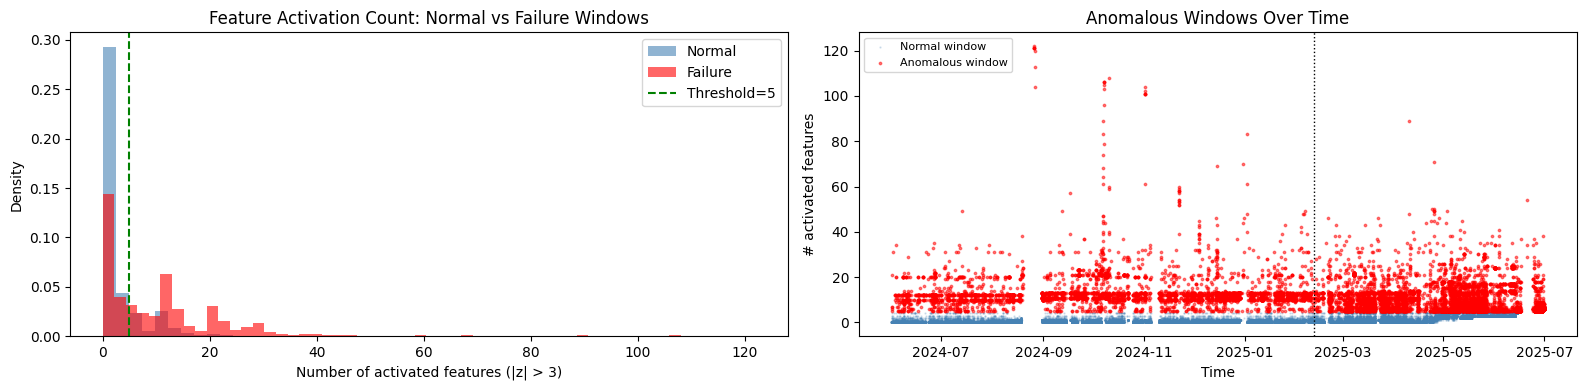

In [3]:
# Compute z-scores relative to train-normal distribution
train_normal = all_sup[(all_sup['split'] == 'train') & (all_sup['label'] == 0)]
feat_means = train_normal[feature_cols].mean()
feat_stds = train_normal[feature_cols].std()
feat_stds = feat_stds.replace(0, 1)  # avoid division by zero
del train_normal; gc.collect()

# Z-score all windows
Z_THRESH = 3.0  # a feature is "activated" if |z| > 3
zscores = (all_sup[feature_cols] - feat_means) / feat_stds
activations = (zscores.abs() > Z_THRESH).astype(int)  # binary: 1 = anomalous feature

# Count activated features per window
all_sup['n_activated'] = activations.sum(axis=1)

# A window is "anomalous" if >= 5 features are activated
MIN_ACTIVATED = 5
all_sup['is_anomalous'] = (all_sup['n_activated'] >= MIN_ACTIVATED).astype(int)

n_anom = all_sup['is_anomalous'].sum()
n_anom_fail = all_sup.loc[all_sup['is_anomalous'] == 1, 'label'].sum()
n_anom_normal = n_anom - n_anom_fail

print(f'Z-score threshold: |z| > {Z_THRESH}')
print(f'Min activated features: {MIN_ACTIVATED}')
print(f'\nAnomalous windows: {n_anom} / {len(all_sup)} ({100*n_anom/len(all_sup):.1f}%)')
print(f'  With failure label: {n_anom_fail} ({100*n_anom_fail/max(n_anom,1):.1f}%)')
print(f'  Without failure label: {n_anom_normal} ({100*n_anom_normal/max(n_anom,1):.1f}%)')
print(f'\nFor comparison:')
print(f'  Total failure windows: {all_sup["label"].sum()}')
print(f'  Failure windows that are anomalous: {n_anom_fail} ({100*n_anom_fail/max(all_sup["label"].sum(),1):.1f}%)')

# Distribution of n_activated
fig, axes = plt.subplots(1, 2, figsize=(16, 4))

ax = axes[0]
ax.hist(all_sup.loc[all_sup['label']==0, 'n_activated'], bins=50, alpha=0.6, color='steelblue', label='Normal', density=True)
ax.hist(all_sup.loc[all_sup['label']==1, 'n_activated'], bins=50, alpha=0.6, color='red', label='Failure', density=True)
ax.axvline(MIN_ACTIVATED, color='green', linestyle='--', label=f'Threshold={MIN_ACTIVATED}')
ax.set_xlabel('Number of activated features (|z| > 3)')
ax.set_ylabel('Density')
ax.set_title('Feature Activation Count: Normal vs Failure Windows')
ax.legend()

ax = axes[1]
ax.scatter(all_sup.loc[all_sup['is_anomalous']==0, 'window_end'],
           all_sup.loc[all_sup['is_anomalous']==0, 'n_activated'],
           s=0.5, alpha=0.2, c='steelblue', label='Normal window')
ax.scatter(all_sup.loc[all_sup['is_anomalous']==1, 'window_end'],
           all_sup.loc[all_sup['is_anomalous']==1, 'n_activated'],
           s=3, alpha=0.5, c='red', label='Anomalous window')
ax.axvline(SPLIT_DATE, color='black', linestyle=':', linewidth=1)
ax.set_xlabel('Time')
ax.set_ylabel('# activated features')
ax.set_title('Anomalous Windows Over Time')
ax.legend(loc='upper left', fontsize=8)

plt.tight_layout()
plt.show()

Total windows: 64,522 | Total failure windows: 1202

z_thresh min_act  Anomalous % of all  Fail det  Precision   Recall
-----------------------------------------------------------------
     2.0       1     49,631    76.9%      1129       2.3%    93.9%
     2.0       3     41,572    64.4%      1093       2.6%    90.9%
     2.0       5     37,145    57.6%      1063       2.9%    88.4%
     2.0      10     32,733    50.7%      1012       3.1%    84.2%
     2.0      15     24,408    37.8%       929       3.8%    77.3%
     2.0      20     19,436    30.1%       869       4.5%    72.3%
     2.5       1     39,538    61.3%      1040       2.6%    86.5%
     2.5       3     25,668    39.8%       917       3.6%    76.3%
     2.5       5     21,046    32.6%       875       4.2%    72.8%
     2.5      10     15,758    24.4%       799       5.1%    66.5%
     2.5      15      6,420    10.0%       535       8.3%    44.5%
     2.5      20      4,764     7.4%       411       8.6%    34.2%
     3.0  

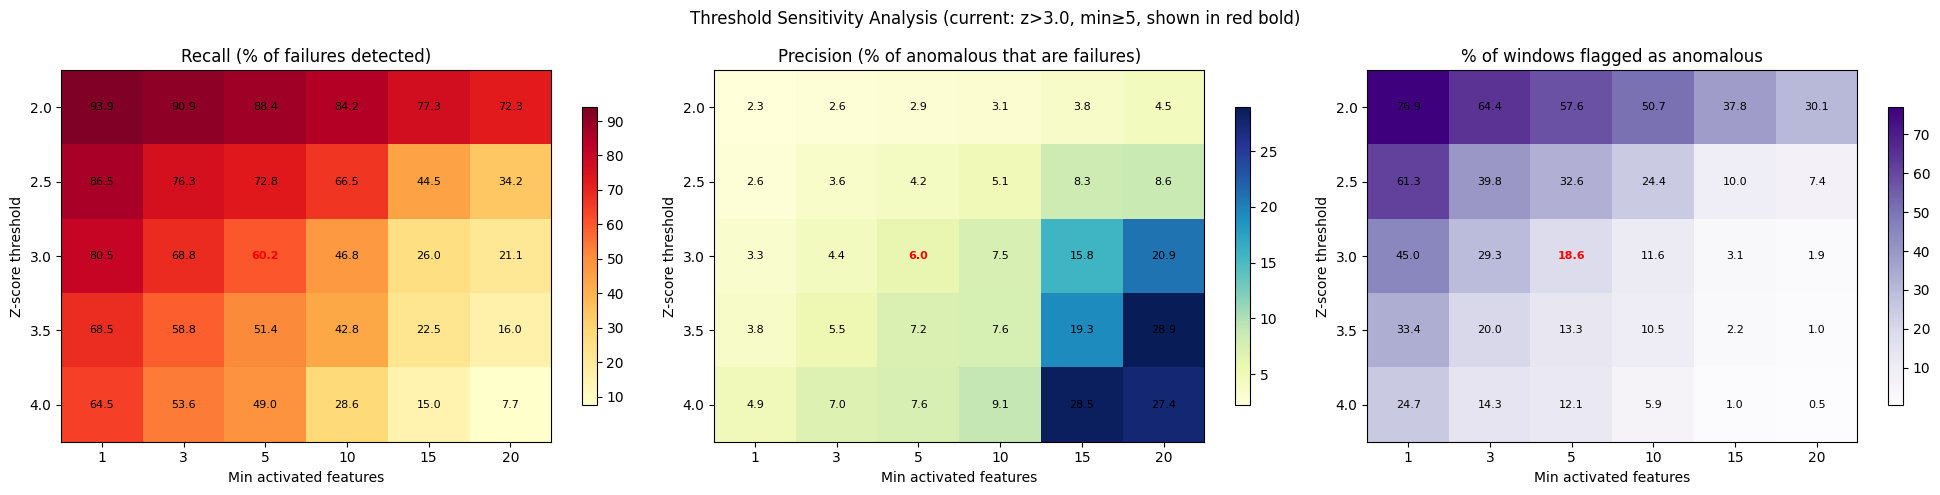


Current setting (z>3.0, min≥5): 60.2% recall, 6.0% precision
Highest recall:    z>2.0, min≥1 → 93.9% recall, 2.3% precision
Highest precision: z>3.5, min≥20 → 16.0% recall, 28.9% precision

The current thresholds balance recall and anomaly volume.


In [4]:
# ── Threshold sensitivity analysis ──
# How do results change with different z-score thresholds and min-activated-features?

z_thresholds = [2.0, 2.5, 3.0, 3.5, 4.0]
min_activated_values = [1, 3, 5, 10, 15, 20]

total_windows = len(all_sup)
total_failures = int(all_sup['label'].sum())

# Precompute activations for each z-threshold
results = []
for z in z_thresholds:
    act_z = (zscores.abs() > z).sum(axis=1)
    for m in min_activated_values:
        is_anom = act_z >= m
        n_anom = int(is_anom.sum())
        n_fail_detected = int(all_sup.loc[is_anom, 'label'].sum())
        precision = 100 * n_fail_detected / max(n_anom, 1)
        recall = 100 * n_fail_detected / max(total_failures, 1)
        results.append({
            'z_thresh': z, 'min_act': m,
            'n_anomalous': n_anom,
            'pct_anomalous': 100 * n_anom / total_windows,
            'fail_detected': n_fail_detected,
            'precision': precision,
            'recall': recall
        })

res_df = pd.DataFrame(results)

# Print summary table
print(f'Total windows: {total_windows:,} | Total failure windows: {total_failures}')
print()
print(f'{"z_thresh":>8} {"min_act":>7} {"Anomalous":>10} {"% of all":>8} {"Fail det":>9} {"Precision":>10} {"Recall":>8}')
print('-' * 65)
for _, r in res_df.iterrows():
    marker = ' ◄' if r['z_thresh'] == Z_THRESH and r['min_act'] == MIN_ACTIVATED else ''
    print(f'{r["z_thresh"]:>8.1f} {r["min_act"]:>7.0f} {r["n_anomalous"]:>10,.0f} {r["pct_anomalous"]:>7.1f}% {r["fail_detected"]:>9.0f} {r["precision"]:>9.1f}% {r["recall"]:>7.1f}%{marker}')

# Heatmaps: precision and recall across threshold combinations
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

for ax, metric, title, cmap in [
    (axes[0], 'recall', 'Recall (% of failures detected)', 'YlOrRd'),
    (axes[1], 'precision', 'Precision (% of anomalous that are failures)', 'YlGnBu'),
    (axes[2], 'pct_anomalous', '% of windows flagged as anomalous', 'Purples'),
]:
    pivot = res_df.pivot(index='z_thresh', columns='min_act', values=metric)
    im = ax.imshow(pivot.values, cmap=cmap, aspect='auto')
    ax.set_xticks(range(len(min_activated_values)))
    ax.set_xticklabels(min_activated_values)
    ax.set_yticks(range(len(z_thresholds)))
    ax.set_yticklabels(z_thresholds)
    ax.set_xlabel('Min activated features')
    ax.set_ylabel('Z-score threshold')
    ax.set_title(title)
    # Annotate cells
    for i in range(len(z_thresholds)):
        for j in range(len(min_activated_values)):
            val = pivot.values[i, j]
            # Highlight current choice
            is_current = (z_thresholds[i] == Z_THRESH and min_activated_values[j] == MIN_ACTIVATED)
            weight = 'bold' if is_current else 'normal'
            color = 'red' if is_current else 'black'
            ax.text(j, i, f'{val:.1f}', ha='center', va='center',
                    fontsize=8, fontweight=weight, color=color)
    plt.colorbar(im, ax=ax, shrink=0.8)

plt.suptitle(f'Threshold Sensitivity Analysis (current: z>{Z_THRESH}, min≥{MIN_ACTIVATED}, shown in red bold)', fontsize=12)
plt.tight_layout()
plt.show()

# Interpretation
best_recall = res_df.loc[res_df['recall'].idxmax()]
best_precision = res_df.loc[res_df['precision'].idxmax()]
current = res_df[(res_df['z_thresh'] == Z_THRESH) & (res_df['min_act'] == MIN_ACTIVATED)].iloc[0]
print(f'\nCurrent setting (z>{Z_THRESH}, min≥{MIN_ACTIVATED}): {current["recall"]:.1f}% recall, {current["precision"]:.1f}% precision')
print(f'Highest recall:    z>{best_recall["z_thresh"]}, min≥{best_recall["min_act"]:.0f} → {best_recall["recall"]:.1f}% recall, {best_recall["precision"]:.1f}% precision')
print(f'Highest precision: z>{best_precision["z_thresh"]}, min≥{best_precision["min_act"]:.0f} → {best_precision["recall"]:.1f}% recall, {best_precision["precision"]:.1f}% precision')
print(f'\nThe current thresholds balance recall and anomaly volume.')

## 2. Feature Activation Profiles

For each anomalous window, we have a binary vector: which of the 340 features are activated (|z| > 3)?

This is the "fingerprint" of each anomaly â€” which sensors are behaving unusually.

In [5]:
# Extract activation profiles for anomalous windows only
anom_mask = all_sup['is_anomalous'] == 1
anom_orig_idx = all_sup.index[anom_mask]  # original indices into all_sup
anom_activations = activations.loc[anom_mask].reset_index(drop=True)
anom_meta = all_sup.loc[anom_mask, ['window_end', 'label', 'split', 'n_activated']].reset_index(drop=True)

print(f'Anomalous windows: {len(anom_activations)}')
print(f'Activation matrix shape: {anom_activations.shape}')

# Which features are most commonly activated?
feat_freq = anom_activations.sum().sort_values(ascending=False)
feat_freq_pct = (feat_freq / len(anom_activations) * 100).round(1)

print(f'\nTop 30 most frequently activated features:')
top30 = feat_freq.head(30)
for f, count in top30.items():
    pct = count / len(anom_activations) * 100
    print(f'  {f:55s} {count:5d} ({pct:5.1f}%)')

# Never-activated features
never_activated = (feat_freq == 0).sum()
print(f'\nFeatures never activated: {never_activated} / {len(feature_cols)}')

Anomalous windows: 12022
Activation matrix shape: (12022, 266)

Top 30 most frequently activated features:
  MW4_LOAD_SIGNAL_min                                      3925 ( 32.6%)
  MW3_BRAKE_CYLINDER_PRESSURE_BOGIE2_max                   3644 ( 30.3%)
  MW4_ENERGY_BRAKING_RESISTANCE_max                        3471 ( 28.9%)
  MW4_ENERGY_BRAKING_RESISTANCE_mean                       3468 ( 28.8%)
  MW2_BRAKE_CYLINDER_PRESSURE_BOGIE1_max                   3258 ( 27.1%)
  MW1_BRAKE_CYLINDER_PRESSURE_BOGIE1_max                   3053 ( 25.4%)
  MW4_BRAKE_CYLINDER_PRESSURE_BOGIE1_max                   3019 ( 25.1%)
  MW4_ENERGY_BRAKING_RESISTANCE_min                        2885 ( 24.0%)
  CW2_BRAKE_CYLINDER_PRESSURE_BOGIE1_min                   2676 ( 22.3%)
  MW2_BRAKE_CYLINDER_PRESSURE_BOGIE2_min                   2661 ( 22.1%)
  CW1_BRAKE_CYLINDER_PRESSURE_BOGIE2_min                   2653 ( 22.1%)
  CW1_BRAKE_CYLINDER_PRESSURE_BOGIE1_min                   2649 ( 22.0%)
  CW2_BRAKE_CYLIN

In [6]:
# ── Deeper look: which activated features are actually failure-relevant? ──

# For each feature: how often does it fire in failure vs normal anomalous windows?
fail_anom = anom_meta['label'] == 1
norm_anom = anom_meta['label'] == 0

baseline_rate = 100 * fail_anom.mean()
top30_feats = feat_freq.head(30).index.tolist()

print(f'{"Feature":<55} {"Total":>6} {"In Fail":>8} {"In Norm":>8} {"Fail Rate":>10}')
print('=' * 95)
for f in top30_feats:
    total = int(anom_activations[f].sum())
    in_fail = int(anom_activations.loc[fail_anom, f].sum())
    in_norm = int(anom_activations.loc[norm_anom, f].sum())
    fail_rate = 100 * in_fail / max(total, 1)
    marker = ' ***' if fail_rate > baseline_rate else ''
    print(f'{f:<55} {total:>6} {in_fail:>8} {in_norm:>8} {fail_rate:>9.1f}%{marker}')

print()
print(f'*** = failure rate > {baseline_rate:.1f}% baseline (more predictive than chance)')

Feature                                                  Total  In Fail  In Norm  Fail Rate
MW4_LOAD_SIGNAL_min                                       3925      398     3527      10.1% ***
MW3_BRAKE_CYLINDER_PRESSURE_BOGIE2_max                    3644      265     3379       7.3% ***
MW4_ENERGY_BRAKING_RESISTANCE_max                         3471      220     3251       6.3% ***
MW4_ENERGY_BRAKING_RESISTANCE_mean                        3468      226     3242       6.5% ***
MW2_BRAKE_CYLINDER_PRESSURE_BOGIE1_max                    3258      153     3105       4.7%
MW1_BRAKE_CYLINDER_PRESSURE_BOGIE1_max                    3053      143     2910       4.7%
MW4_BRAKE_CYLINDER_PRESSURE_BOGIE1_max                    3019      138     2881       4.6%
MW4_ENERGY_BRAKING_RESISTANCE_min                         2885      113     2772       3.9%
CW2_BRAKE_CYLINDER_PRESSURE_BOGIE1_min                    2676      117     2559       4.4%
MW2_BRAKE_CYLINDER_PRESSURE_BOGIE2_min                    2661  

In [7]:
# Group by physical sensor (strip _min/_max/_mean/_std/_flips suffix)
print()
print('─' * 60)
print('Aggregated by physical sensor (top 15):')
print('─' * 60)
sensor_info = {}
for f in feat_freq.index:
    for suf in ['_min', '_max', '_mean', '_std', '_flips']:
        if f.endswith(suf):
            sensor = f[:-len(suf)]
            if sensor not in sensor_info:
                sensor_info[sensor] = {'total': 0, 'active_feats': 0, 'all_feats': 0, 'which': []}
            sensor_info[sensor]['total'] += int(feat_freq[f])
            sensor_info[sensor]['all_feats'] += 1
            if int(feat_freq[f]) > 0:
                sensor_info[sensor]['active_feats'] += 1
                sensor_info[sensor]['which'].append(suf[1:])  # strip leading _
            break

sorted_sensors = sorted(sensor_info.items(), key=lambda x: x[1]['total'], reverse=True)
print(f'{"Sensor":<45} {"Activations":>12} {"Active/Total":>13}  Which')
print('-' * 95)
for sensor, info in sorted_sensors[:15]:
    which_str = ', '.join(info['which'])
    print(f'{sensor:<45} {info["total"]:>12} {info["active_feats"]:>6}/{info["all_feats"]:<6}  {which_str}')


────────────────────────────────────────────────────────────
Aggregated by physical sensor (top 15):
────────────────────────────────────────────────────────────
Sensor                                         Activations  Active/Total  Which
-----------------------------------------------------------------------------------------------
MW4_ENERGY_BRAKING_RESISTANCE                         9824      3/3       max, mean, min
MW3_BRAKE_CYLINDER_PRESSURE_BOGIE2                    6282      3/3       max, min, mean
MW2_BRAKE_CYLINDER_PRESSURE_BOGIE1                    5883      2/3       max, min
MW1_BRAKE_CYLINDER_PRESSURE_BOGIE1                    5684      2/3       max, min
MW4_BRAKE_CYLINDER_PRESSURE_BOGIE1                    5616      2/3       max, min
CW1_BRAKE_CYLINDER_PRESSURE_BOGIE2                    5115      2/3       min, max
MW2_BRAKE_CYLINDER_PRESSURE_BOGIE2                    5086      2/3       min, max
MW3_BRAKE_CYLINDER_PRESSURE_BOGIE1                    5068      2/3 

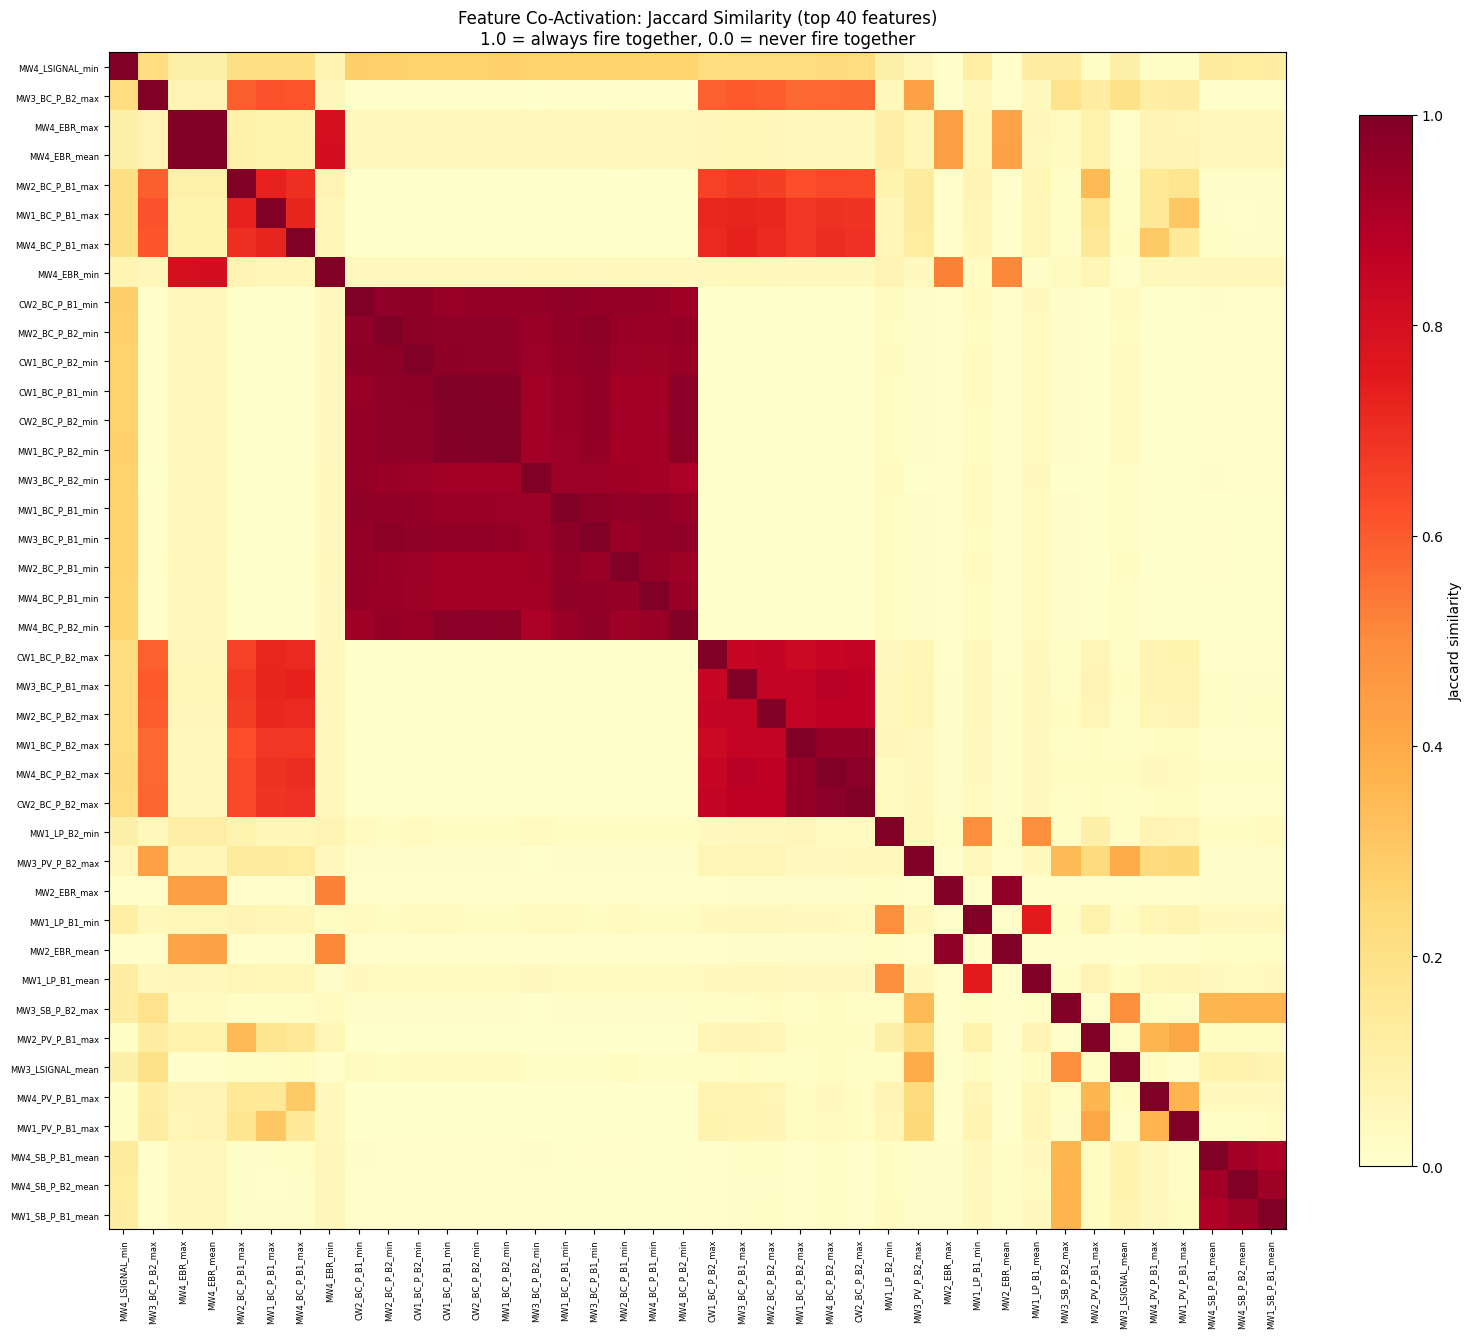

Diagonal = 1.0 (feature with itself)
Off-diagonal bright blocks = features that reliably co-activate
These blocks are what the clustering algorithm discovers automatically.


In [8]:
# ── Option A: Feature Co-Activation Matrix (Jaccard Similarity) ──
# For each pair of features: of the windows where either fires, how often do BOTH fire?
# Jaccard = |A ∩ B| / |A ∪ B|  (0 = never together, 1 = always together)

top40_feats = feat_freq.head(40).index.tolist()
act_matrix = anom_activations[top40_feats].values
n_feats_40 = len(top40_feats)

# Compute pairwise Jaccard similarity
jaccard_sim = np.zeros((n_feats_40, n_feats_40))
for i in range(n_feats_40):
    for j in range(n_feats_40):
        intersection = (act_matrix[:, i] & act_matrix[:, j]).sum()
        union = (act_matrix[:, i] | act_matrix[:, j]).sum()
        jaccard_sim[i, j] = intersection / max(union, 1)

# Short labels for readability
short_labels = [f.replace('PRESSURE', 'P').replace('BOGIE', 'B').replace('BRAKE_CYLINDER', 'BC')
                .replace('SPRING_BRAKE', 'SB').replace('PROPORTIONAL_VALVE', 'PV')
                .replace('PNEUMATIC_BRAKING_FORCE', 'PBF').replace('LOAD_', 'L')
                .replace('MAIN_RESERVOIR', 'MR').replace('ENERGY_BRAKING_RESISTANCE', 'EBR')
                for f in top40_feats]

fig, ax = plt.subplots(figsize=(16, 14))
im = ax.imshow(jaccard_sim, cmap='YlOrRd', vmin=0, vmax=1)
ax.set_xticks(range(len(short_labels)))
ax.set_yticks(range(len(short_labels)))
ax.set_xticklabels(short_labels, rotation=90, fontsize=6)
ax.set_yticklabels(short_labels, fontsize=6)
ax.set_title('Feature Co-Activation: Jaccard Similarity (top 40 features)\n1.0 = always fire together, 0.0 = never fire together')
plt.colorbar(im, ax=ax, label='Jaccard similarity', shrink=0.8)
plt.tight_layout()
plt.show()

print(f"Diagonal = 1.0 (feature with itself)")
print(f"Off-diagonal bright blocks = features that reliably co-activate")
print(f"These blocks are what the clustering algorithm discovers automatically.")

## 3. Feature Clustering

We cluster **features** (not windows) by their co-activation patterns. Features that consistently fire together across anomalous windows are grouped into **feature clusters (FCs)**. This is the core of our subsystem-aware approach: each FC represents a group of sensors that share a common degradation signature.

In [9]:
# Filter to features that are activated in at least 1% of anomalous windows
min_freq = max(int(len(anom_activations) * 0.01), 2)
active_feats = feat_freq[feat_freq >= min_freq].index.tolist()
print(f'Features activated in >= {min_freq} windows: {len(active_feats)} / {len(feature_cols)}')


Features activated in >= 120 windows: 130 / 266


In [10]:
# ── Heuristic A: Jaccard distance on feature co-activation ──
feat_binary = anom_activations[active_feats].values  # windows x features
feat_dist_jaccard = pdist(feat_binary.T, metric='jaccard')
Z_feat_a = linkage(feat_dist_jaccard, method='average')
feat_labels_a = fcluster(Z_feat_a, t=0.7, criterion='distance')

heuristic_a = {}
for f, cl in zip(active_feats, feat_labels_a):
    heuristic_a.setdefault(int(cl), []).append(f)
n_clusters_a = len(heuristic_a)

# ── Heuristic B: Correlation-based clustering ──
anom_data = all_sup.loc[anom_orig_idx, active_feats]
corr_matrix = anom_data.corr().abs()
corr_dist = 1 - corr_matrix.values
np.fill_diagonal(corr_dist, 0)
corr_dist = np.clip(corr_dist, 0, None)
corr_dist_condensed = squareform(corr_dist)
Z_feat_b = linkage(corr_dist_condensed, method='average')
feat_labels_b = fcluster(Z_feat_b, t=0.5, criterion='distance')

heuristic_b = {}
for f, cl in zip(active_feats, feat_labels_b):
    heuristic_b.setdefault(int(cl), []).append(f)
n_clusters_b = len(heuristic_b)

print(f"Heuristic A (Jaccard): {n_clusters_a} clusters")
print(f"Heuristic B (Correlation): {n_clusters_b} clusters")
print()
print("Heuristic B clusters (top 10 by size):")
for cl_id in sorted(heuristic_b.keys(), key=lambda x: len(heuristic_b[x]), reverse=True)[:10]:
    feats = heuristic_b[cl_id]
    cl_active = anom_activations[feats].any(axis=1)
    n_windows = cl_active.sum()
    n_fail = all_sup.loc[anom_orig_idx[cl_active.values], 'label'].sum()
    fail_pct = 100 * n_fail / max(n_windows, 1)
    sensors = set()
    for f in feats:
        for suffix in ['_min', '_max', '_mean', '_std', '_flips']:
            if f.endswith(suffix):
                sensors.add(f[:-len(suffix)])
                break
    print(f"  C{cl_id}: {len(feats)} features, {len(sensors)} sensors, {n_windows} windows, {fail_pct:.1f}% failure")

Heuristic A (Jaccard): 31 clusters
Heuristic B (Correlation): 17 clusters

Heuristic B clusters (top 10 by size):
  C11: 41 features, 20 sensors, 3482 windows, 11.3% failure
  C15: 18 features, 18 sensors, 2985 windows, 10.5% failure
  C16: 13 features, 12 sensors, 2794 windows, 4.8% failure
  C17: 10 features, 10 sensors, 4938 windows, 7.7% failure
  C13: 8 features, 3 sensors, 1737 windows, 18.0% failure
  C10: 7 features, 6 sensors, 1411 windows, 8.2% failure
  C14: 6 features, 2 sensors, 3549 windows, 6.9% failure
  C6: 6 features, 2 sensors, 537 windows, 14.7% failure
  C1: 4 features, 4 sensors, 679 windows, 10.6% failure
  C8: 3 features, 1 sensors, 1702 windows, 8.3% failure


In [11]:
# -- All 31 feature clusters (Heuristic A) with details --
print(f'{"FC":>4} {"Feats":>5} {"Sensors":>7} {"Windows":>7} {"Fail%":>6}  Top Features')
print('='*100)

for cl_id in sorted(heuristic_a.keys()):
    feats = heuristic_a[cl_id]
    sensors = set()
    for f in feats:
        for suf in ['_min', '_max', '_mean', '_std', '_flips']:
            if f.endswith(suf):
                sensors.add(f[:-len(suf)])
                break
    cl_active = anom_activations[feats].any(axis=1)
    n_win = cl_active.sum()
    n_fail = all_sup.loc[anom_orig_idx[cl_active.values], 'label'].sum()
    fail_pct = 100 * n_fail / max(n_win, 1)
    top3 = ', '.join([f[:42] for f in feats[:3]])
    if len(feats) > 3:
        top3 += ', ...'
    print(f'FC{cl_id:>2} {len(feats):>5} {len(sensors):>7} {n_win:>7} {fail_pct:>5.1f}%  {top3}')

# Summary
print()
print('='*60)
print(f'Total: {len(heuristic_a)} feature groups, {sum(len(v) for v in heuristic_a.values())} features')
single = sum(1 for v in heuristic_a.values() if len(v) == 1)
print(f'Single-feature groups: {single}')
print(f'Multi-feature groups: {len(heuristic_a) - single}')

  FC Feats Sensors Windows  Fail%  Top Features
FC 1     4       4     679  10.6%  CW1_SPRING_BRAKE_ACTIVE_BOGIE2_flips, CW2_SPRING_BRAKE_ACTIVE_BOGIE2_flips, CW1_SPRING_BRAKE_ACTIVE_BOGIE1_flips, ...
FC 2     1       1     490   7.8%  CW1_COMPRESSOR_RUNNING_flips
FC 3     1       1     344  15.4%  CW2_COMPRESSOR_RUNNING_flips
FC 4    10      10    4938   7.7%  MW3_BRAKE_CYLINDER_PRESSURE_BOGIE2_max, MW2_BRAKE_CYLINDER_PRESSURE_BOGIE1_max, MW1_BRAKE_CYLINDER_PRESSURE_BOGIE1_max, ...
FC 5     3       3    1876   4.9%  MW2_PROPORTIONAL_VALVE_PRESSURE_BOGIE1_max, MW4_PROPORTIONAL_VALVE_PRESSURE_BOGIE1_max, MW1_PROPORTIONAL_VALVE_PRESSURE_BOGIE1_max
FC 6     4       4    1097  10.2%  MW1_PNEUMATIC_BRAKING_FORCE_BOGIE2_max, MW2_PNEUMATIC_BRAKING_FORCE_BOGIE2_max, MW2_PNEUMATIC_BRAKING_FORCE_BOGIE1_max, ...
FC 7     4       4     259  12.0%  MW3_PNEUMATIC_BRAKING_FORCE_BOGIE1_max, MW4_PNEUMATIC_BRAKING_FORCE_BOGIE1_max, MW4_PNEUMATIC_BRAKING_FORCE_BOGIE2_max, ...
FC 8     3       3     701  

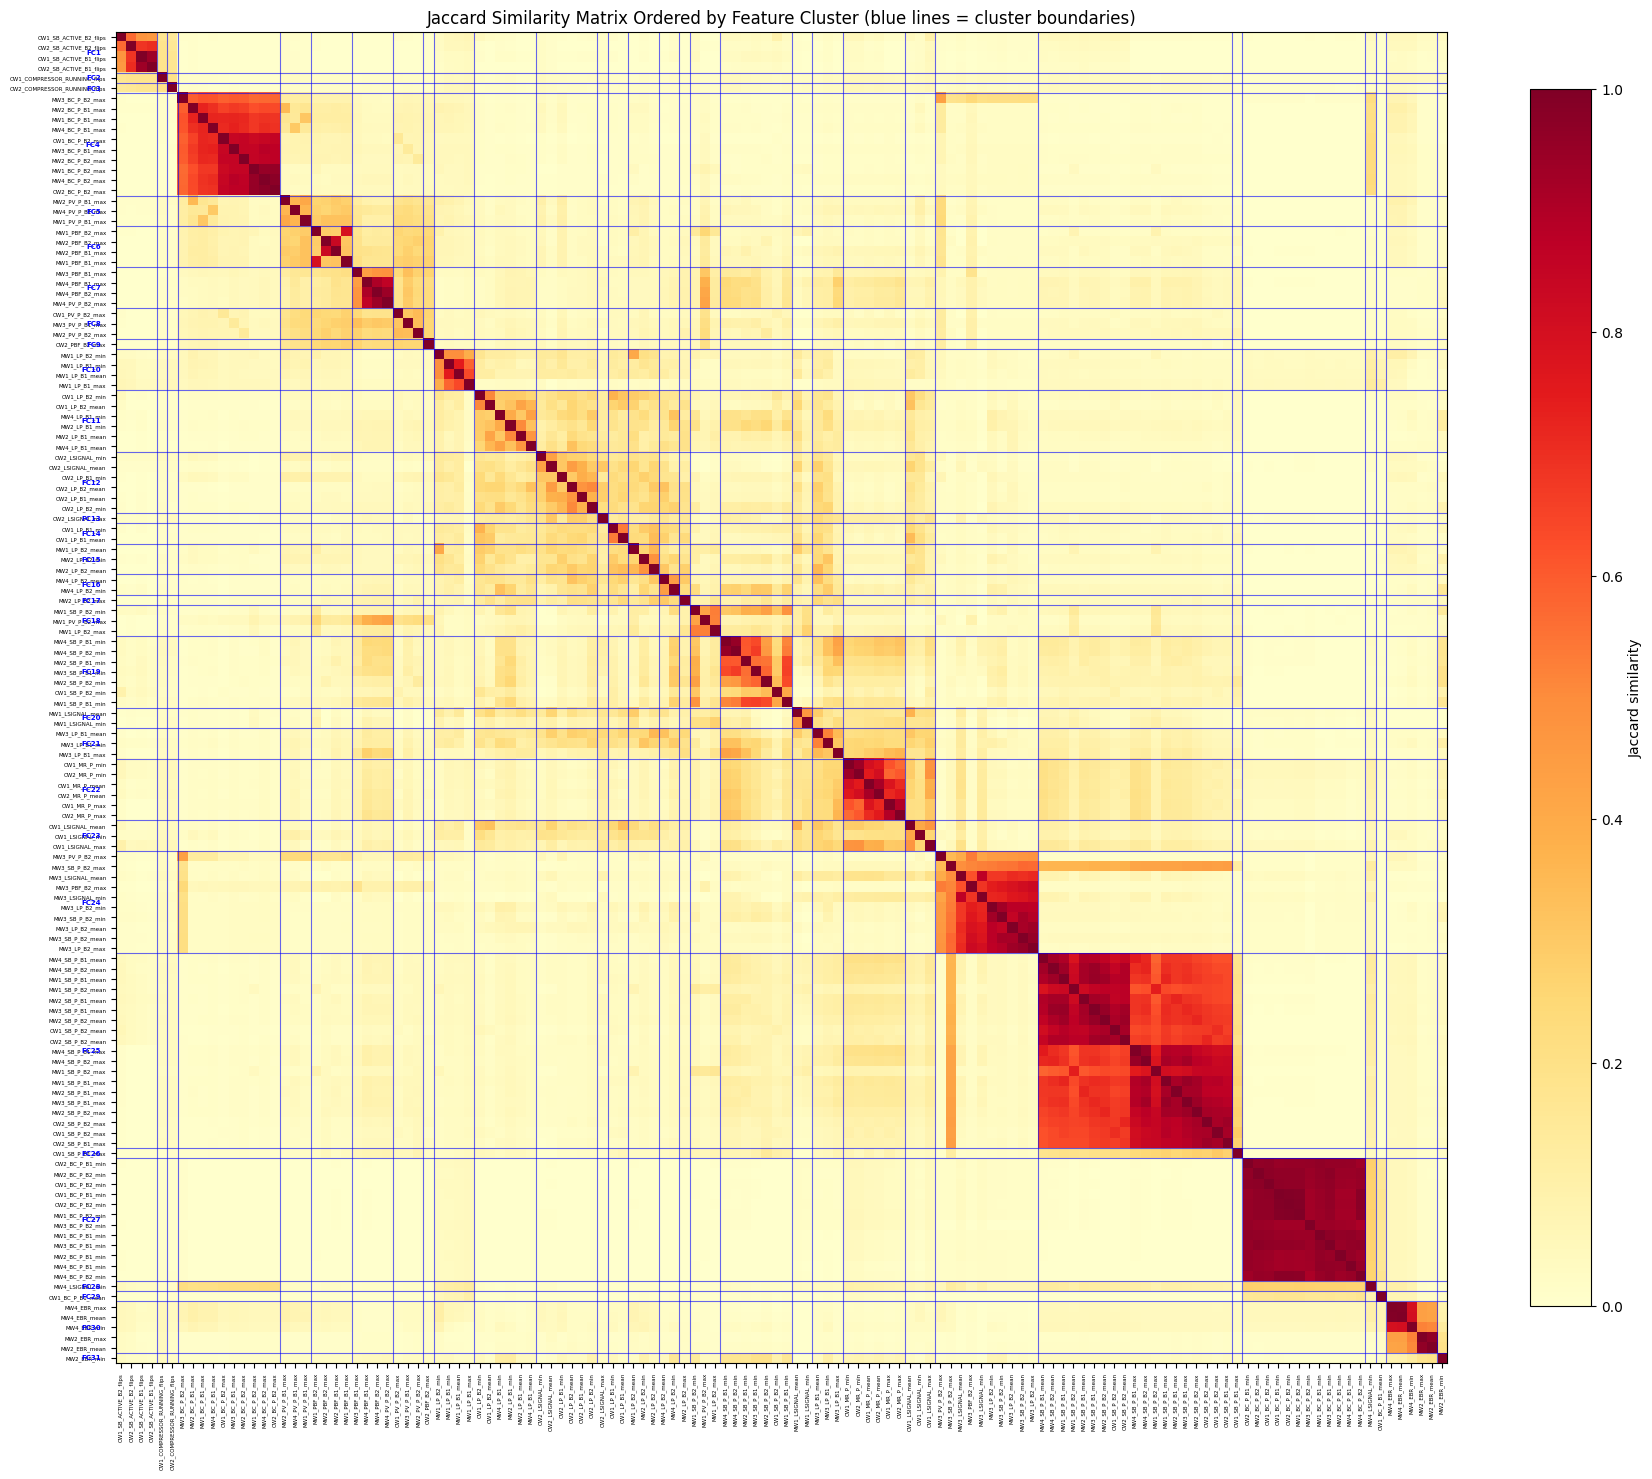

Total features shown: 130
Bright blocks along the diagonal = features within the same cluster co-activate.
Off-diagonal bright spots = clusters that tend to fire together.


In [12]:
# ── Option C: Clustered Co-Activation Heatmap (Jaccard Similarity) ──
# Same Jaccard similarity but reordered by feature cluster assignment
# This reveals the block-diagonal structure that clustering discovered

# Get all active features ordered by cluster
fc_order = []
fc_boundaries = []
pos = 0
for fc in sorted(heuristic_a.keys()):
    feats_active = [f for f in heuristic_a[fc] if f in active_feats]
    if feats_active:
        fc_order.extend(feats_active)
        fc_boundaries.append(pos)
        pos += len(feats_active)

# Compute Jaccard similarity in cluster order
act_ordered = anom_activations[fc_order].values
n_f = act_ordered.shape[0]
n_cols = len(fc_order)

jaccard_ordered = np.zeros((n_cols, n_cols))
for i in range(n_cols):
    for j in range(i, n_cols):
        intersection = (act_ordered[:, i] & act_ordered[:, j]).sum()
        union = (act_ordered[:, i] | act_ordered[:, j]).sum()
        val = intersection / max(union, 1)
        jaccard_ordered[i, j] = val
        jaccard_ordered[j, i] = val

# Short labels
short = [f.replace('PRESSURE', 'P').replace('BOGIE', 'B').replace('BRAKE_CYLINDER', 'BC')
         .replace('SPRING_BRAKE', 'SB').replace('PROPORTIONAL_VALVE', 'PV')
         .replace('PNEUMATIC_BRAKING_FORCE', 'PBF').replace('LOAD_', 'L')
         .replace('MAIN_RESERVOIR', 'MR').replace('ENERGY_BRAKING_RESISTANCE', 'EBR')
         for f in fc_order]

fig, ax = plt.subplots(figsize=(18, 16))
im = ax.imshow(jaccard_ordered, cmap='YlOrRd', vmin=0, vmax=1)

# Draw cluster boundary lines
for b in fc_boundaries[1:]:
    ax.axhline(b - 0.5, color='blue', linewidth=0.8, alpha=0.6)
    ax.axvline(b - 0.5, color='blue', linewidth=0.8, alpha=0.6)

# Label clusters on the side
fc_idx = 0
for fc in sorted(heuristic_a.keys()):
    feats_active = [f for f in heuristic_a[fc] if f in active_feats]
    if feats_active:
        mid = fc_boundaries[fc_idx] + len(feats_active) / 2 - 0.5
        ax.text(-2, mid, f'FC{fc}', fontsize=5, ha='right', va='center', color='blue', fontweight='bold')
        fc_idx += 1

ax.set_xticks(range(len(short)))
ax.set_yticks(range(len(short)))
ax.set_xticklabels(short, rotation=90, fontsize=4)
ax.set_yticklabels(short, fontsize=4)
ax.set_title('Jaccard Similarity Matrix Ordered by Feature Cluster (blue lines = cluster boundaries)')
plt.colorbar(im, ax=ax, label='Jaccard similarity', shrink=0.8)
plt.tight_layout()
plt.show()

print(f"Total features shown: {len(fc_order)}")
print("Bright blocks along the diagonal = features within the same cluster co-activate.")
print("Off-diagonal bright spots = clusters that tend to fire together.")

In [13]:
# ── Same-sensor redundancy analysis ──
# Supervisor feedback: if min/mean/max of same sensor all fire together, are they redundant?
# Answer: Yes, same-sensor aggregations are correlated by construction.
# The REAL clustering signal is cross-sensor co-activation.

# Classify each cluster
print("Feature vs Sensor redundancy analysis:")
print("="*90)
print(f"{'FC':>4} {'Feats':>5} {'Sensors':>7} {'Type':<25} {'Redundancy':>10}")
print("-"*90)

single_sensor_clusters = 0
multi_sensor_clusters = 0
total_redundant_feats = 0

for cl_id in sorted(heuristic_a.keys()):
    feats = heuristic_a[cl_id]
    sensors = set()
    for f in feats:
        for suf in ['_min', '_max', '_mean', '_std', '_flips']:
            if f.endswith(suf):
                sensors.add(f[:-len(suf)])
                break
    
    n_feats = len(feats)
    n_sensors = len(sensors)
    
    if n_feats == 1:
        ctype = "single feature"
        redundancy = "-"
    elif n_sensors == 1:
        ctype = "same-sensor aggregations"
        single_sensor_clusters += 1
        redundancy = f"{n_feats - 1} redundant"
        total_redundant_feats += n_feats - 1
    elif n_feats == n_sensors:
        ctype = "cross-sensor (no redundancy)"
        multi_sensor_clusters += 1
        redundancy = "0"
    else:
        ctype = "mixed (cross-sensor + agg)"
        multi_sensor_clusters += 1
        redundancy = f"{n_feats - n_sensors} redundant"
        total_redundant_feats += n_feats - n_sensors
    
    print(f"FC{cl_id:>2} {n_feats:>5} {n_sensors:>7} {ctype:<25} {redundancy:>10}")

print()
print("="*60)
print(f"Single-sensor clusters (pure aggregation redundancy): {single_sensor_clusters}")
print(f"Multi-sensor clusters (genuine cross-sensor patterns): {multi_sensor_clusters}")
print(f"Single-feature clusters: {sum(1 for v in heuristic_a.values() if len(v) == 1)}")
print(f"Total features: {sum(len(v) for v in heuristic_a.values())}")
print(f"Total unique sensors: {len(set(s for feats in heuristic_a.values() for f in feats for suf in ['_min','_max','_mean','_std','_flips'] if f.endswith(suf) for s in [f[:-len(suf)]]))}")
print(f"Redundant features (same-sensor duplicates): {total_redundant_feats}")
print()
print("Interpretation:")
print("Same-sensor aggregations (min/mean/max) co-activating is expected and trivial.")
print("The key finding is CROSS-SENSOR co-activation: sensors from different physical")
print("locations firing together reveals shared degradation mechanisms.")
print("At the sensor level, the 31 FCs collapse to fewer independent groups.")

Feature vs Sensor redundancy analysis:
  FC Feats Sensors Type                      Redundancy
------------------------------------------------------------------------------------------
FC 1     4       4 cross-sensor (no redundancy)          0
FC 2     1       1 single feature                     -
FC 3     1       1 single feature                     -
FC 4    10      10 cross-sensor (no redundancy)          0
FC 5     3       3 cross-sensor (no redundancy)          0
FC 6     4       4 cross-sensor (no redundancy)          0
FC 7     4       4 cross-sensor (no redundancy)          0
FC 8     3       3 cross-sensor (no redundancy)          0
FC 9     1       1 single feature                     -
FC10     4       2 mixed (cross-sensor + agg) 2 redundant
FC11     6       3 mixed (cross-sensor + agg) 3 redundant
FC12     6       3 mixed (cross-sensor + agg) 3 redundant
FC13     1       1 single feature                     -
FC14     2       1 same-sensor aggregations  1 redundant
FC15 

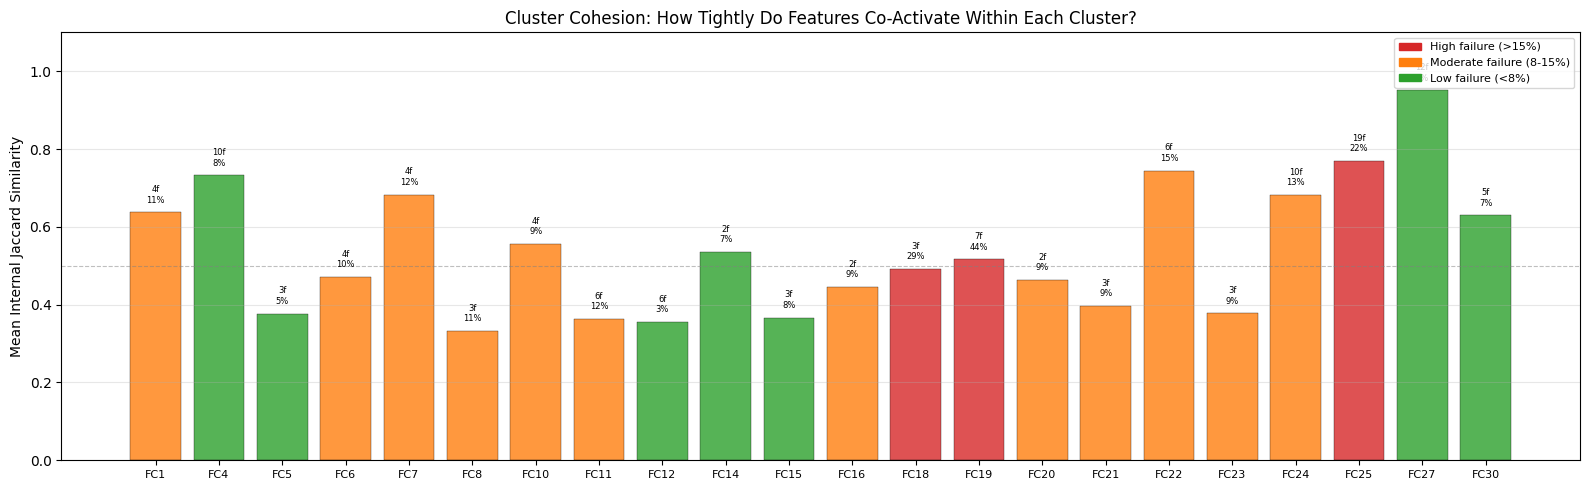

Multi-feature clusters: 22
Mean cohesion: 0.540
Clusters with cohesion > 0.5: 11
Clusters with cohesion > 0.3: 22

Annotation: Nf = number of features, % = failure rate


In [14]:
# ── Cluster Cohesion: Average Internal Jaccard Similarity per FC ──
# For each cluster with >= 2 features, compute the mean pairwise Jaccard similarity

fc_ids_all = sorted(heuristic_a.keys())
fc_labels_plot = []
fc_cohesion = []
fc_sizes = []
fc_fail_pcts = []

for fc in fc_ids_all:
    feats = [f for f in heuristic_a[fc] if f in active_feats]
    if len(feats) < 2:
        continue
    
    act_sub = anom_activations[feats].values
    n = len(feats)
    jac_vals = []
    for i in range(n):
        for j in range(i + 1, n):
            inter = (act_sub[:, i] & act_sub[:, j]).sum()
            union = (act_sub[:, i] | act_sub[:, j]).sum()
            jac_vals.append(inter / max(union, 1))
    
    cl_act = anom_activations[feats].any(axis=1)
    n_win = cl_act.sum()
    n_fail = int(anom_meta.loc[cl_act, 'label'].sum())
    
    fc_labels_plot.append(f'FC{fc}')
    fc_cohesion.append(np.mean(jac_vals))
    fc_sizes.append(len(feats))
    fc_fail_pcts.append(100 * n_fail / max(n_win, 1))

# Plot
fig, ax = plt.subplots(figsize=(16, 5))
x = np.arange(len(fc_labels_plot))
colors = ['#d62728' if fp > 15 else '#ff7f0e' if fp > 8 else '#2ca02c' for fp in fc_fail_pcts]
bars = ax.bar(x, fc_cohesion, color=colors, alpha=0.8, edgecolor='black', linewidth=0.3)

# Annotate with size and failure %
for i, (coh, sz, fp) in enumerate(zip(fc_cohesion, fc_sizes, fc_fail_pcts)):
    ax.text(i, coh + 0.02, f'{sz}f\n{fp:.0f}%', ha='center', va='bottom', fontsize=6)

ax.set_xticks(x)
ax.set_xticklabels(fc_labels_plot, fontsize=8)
ax.set_ylabel('Mean Internal Jaccard Similarity')
ax.set_title('Cluster Cohesion: How Tightly Do Features Co-Activate Within Each Cluster?')
ax.set_ylim(0, 1.1)
ax.axhline(0.5, color='gray', linestyle='--', linewidth=0.8, alpha=0.5, label='0.5 threshold')
ax.grid(axis='y', alpha=0.3)

# Legend for colors
from matplotlib.patches import Patch
legend_patches = [
    Patch(color='#d62728', label='High failure (>15%)'),
    Patch(color='#ff7f0e', label='Moderate failure (8-15%)'),
    Patch(color='#2ca02c', label='Low failure (<8%)')
]
ax.legend(handles=legend_patches, loc='upper right', fontsize=8)

plt.tight_layout()
plt.show()

# Summary stats
print(f'Multi-feature clusters: {len(fc_cohesion)}')
print(f'Mean cohesion: {np.mean(fc_cohesion):.3f}')
print(f'Clusters with cohesion > 0.5: {sum(1 for c in fc_cohesion if c > 0.5)}')
print(f'Clusters with cohesion > 0.3: {sum(1 for c in fc_cohesion if c > 0.3)}')
print()
print('Annotation: Nf = number of features, % = failure rate')

### 3.1 Heuristic Comparison: Jaccard vs Correlation Clustering

To validate robustness, we compare two independent clustering approaches on the same features:
- **Heuristic A (Jaccard):** clusters features by binary co-activation similarity
- **Heuristic B (Correlation):** clusters features by absolute Pearson correlation on continuous values

If both produce similar groupings, the discovered structure is robust and not an artifact of the distance metric.

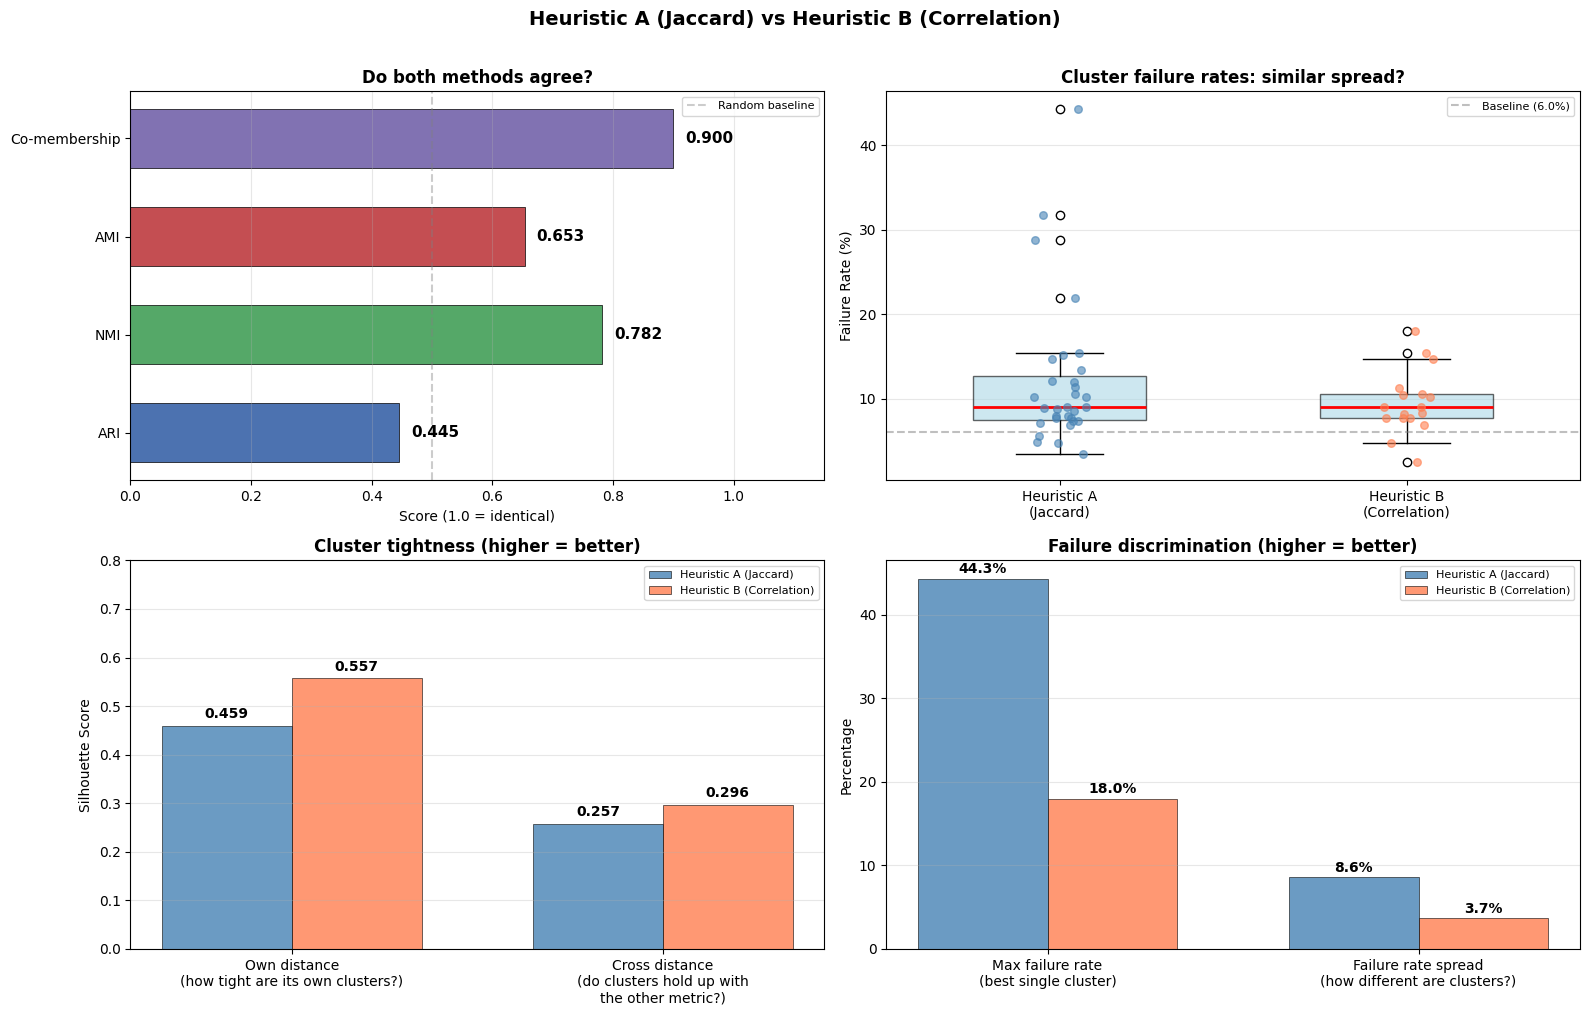

STATISTICAL COMPARISON: HEURISTIC A vs HEURISTIC B

Metric                                     Heuristic A   Heuristic B
........................................     (Jaccard) (Correlation)
----------------------------------------------------------------------
Number of clusters                                  31            17
Mean cluster size                                  4.2           7.6
Size entropy (lower=more decisive)               3.084         2.310
Silhouette (own distance)                        0.459         0.557
Silhouette (cross distance)                      0.257         0.296
Max failure rate (%)                              44.3          18.0
Failure rate range (%)                            40.9          15.5
Failure rate spread (std)                         8.59          3.68

--- Agreement Between A and B ---
Adjusted Rand Index (ARI)                        0.445
Normalized Mutual Information (NMI)              0.782
Adjusted Mutual Information (AMI)         

In [15]:
# ── Numerical comparison of Heuristic A vs Heuristic B ──
from sklearn.metrics import (adjusted_rand_score, normalized_mutual_info_score,
                             adjusted_mutual_info_score, silhouette_score as sil_score)
from scipy.stats import entropy as sp_entropy

ari = adjusted_rand_score(feat_labels_a, feat_labels_b)
nmi = normalized_mutual_info_score(feat_labels_a, feat_labels_b)
ami = adjusted_mutual_info_score(feat_labels_a, feat_labels_b)

# Co-membership agreement
def co_membership_agreement(la, lb):
    n = len(la)
    agree = sum(1 for i in range(n) for j in range(i+1, n)
                if (la[i] == la[j]) == (lb[i] == lb[j]))
    return agree / (n * (n - 1) / 2)

co_agree = co_membership_agreement(feat_labels_a, feat_labels_b)

# Silhouette scores
dist_a_sq = squareform(feat_dist_jaccard)
dist_b_sq = 1 - all_sup.loc[anom_orig_idx, active_feats].corr().abs().values
np.fill_diagonal(dist_b_sq, 0); dist_b_sq = np.clip(dist_b_sq, 0, None)

sil_a = sil_score(dist_a_sq, feat_labels_a, metric='precomputed')
sil_b = sil_score(dist_b_sq, feat_labels_b, metric='precomputed')
sil_a_x = sil_score(dist_b_sq, feat_labels_a, metric='precomputed')
sil_b_x = sil_score(dist_a_sq, feat_labels_b, metric='precomputed')

# Failure rate per cluster for both heuristics
def cluster_failure_rates(heur_dict):
    rates = []
    for cl_id in sorted(heur_dict.keys()):
        feats = heur_dict[cl_id]
        cl_active = anom_activations[feats].any(axis=1)
        n_w = cl_active.sum()
        if n_w == 0: continue
        n_f = all_sup.loc[anom_orig_idx[cl_active.values], 'label'].sum()
        rates.append(100 * n_f / n_w)
    return rates

fr_a = cluster_failure_rates(heuristic_a)
fr_b = cluster_failure_rates(heuristic_b)

# Failure discrimination
def failure_discrimination(rates):
    fr = np.array(rates)
    wstd = np.std(fr)
    return float(wstd), float(fr.max() - fr.min()), float(fr.max())

spread_a, range_a, max_a = failure_discrimination(fr_a)
spread_b, range_b, max_b = failure_discrimination(fr_b)

# Size entropy
sizes_a = np.array([np.sum(feat_labels_a == c) for c in set(feat_labels_a)])
sizes_b = np.array([np.sum(feat_labels_b == c) for c in set(feat_labels_b)])
ent_a = sp_entropy(sizes_a / sizes_a.sum())
ent_b = sp_entropy(sizes_b / sizes_b.sum())

BASELINE_FAIL_PCT = 100 * all_sup.loc[anom_orig_idx, 'label'].mean()

# ── 2x2 layout: each metric gets its own subplot with proper scale ──
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Panel 1 (top-left): Agreement — how similar are the two methods?
ax = axes[0, 0]
metrics = ['ARI', 'NMI', 'AMI', 'Co-membership']
values = [ari, nmi, ami, co_agree]
colors = ['#4c72b0', '#55a868', '#c44e52', '#8172b2']
bars = ax.barh(metrics, values, color=colors, edgecolor='black', linewidth=0.5, height=0.6)
for bar, v in zip(bars, values):
    ax.text(v + 0.02, bar.get_y() + bar.get_height()/2,
            f'{v:.3f}', ha='left', va='center', fontsize=11, fontweight='bold')
ax.set_xlim(0, 1.15)
ax.set_xlabel('Score (1.0 = identical)')
ax.set_title('Do both methods agree?', fontsize=12, fontweight='bold')
ax.axvline(0.5, color='grey', ls='--', alpha=0.4, label='Random baseline')
ax.legend(fontsize=8)
ax.grid(axis='x', alpha=0.3)

# Panel 2 (top-right): Failure rate distribution
ax = axes[0, 1]
ax.boxplot([fr_a, fr_b], labels=['Heuristic A\n(Jaccard)', 'Heuristic B\n(Correlation)'],
           widths=0.5, patch_artist=True,
           boxprops=dict(facecolor='lightblue', alpha=0.6),
           medianprops=dict(color='red', linewidth=2))
for i, (rates, color) in enumerate([(fr_a, 'steelblue'), (fr_b, 'coral')]):
    jitter = np.random.default_rng(42).uniform(-0.08, 0.08, len(rates))
    ax.scatter([i+1]*len(rates) + jitter, rates, color=color, alpha=0.6, s=30, zorder=5)
ax.axhline(BASELINE_FAIL_PCT, color='grey', ls='--', alpha=0.5, label=f'Baseline ({BASELINE_FAIL_PCT:.1f}%)')
ax.set_ylabel('Failure Rate (%)')
ax.set_title('Cluster failure rates: similar spread?', fontsize=12, fontweight='bold')
ax.legend(fontsize=8)
ax.grid(axis='y', alpha=0.3)

# Panel 3 (bottom-left): Silhouette — cluster tightness (same 0-1 scale)
ax = axes[1, 0]
x = np.arange(2)
w = 0.35
b1 = ax.bar(x - w/2, [sil_a, sil_a_x], w, label='Heuristic A (Jaccard)',
            color='steelblue', alpha=0.8, edgecolor='black', linewidth=0.5)
b2 = ax.bar(x + w/2, [sil_b, sil_b_x], w, label='Heuristic B (Correlation)',
            color='coral', alpha=0.8, edgecolor='black', linewidth=0.5)
for bars_g in [b1, b2]:
    for bar in bars_g:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, h + 0.01,
                f'{h:.3f}', ha='center', va='bottom', fontsize=10, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(['Own distance\n(how tight are its own clusters?)',
                     'Cross distance\n(do clusters hold up with\nthe other metric?)'])
ax.set_ylim(0, 0.8)
ax.set_ylabel('Silhouette Score')
ax.set_title('Cluster tightness (higher = better)', fontsize=12, fontweight='bold')
ax.legend(fontsize=8)
ax.grid(axis='y', alpha=0.3)

# Panel 4 (bottom-right): Failure discrimination (same % scale)
ax = axes[1, 1]
x = np.arange(2)
b1 = ax.bar(x - w/2, [max_a, spread_a], w, label='Heuristic A (Jaccard)',
            color='steelblue', alpha=0.8, edgecolor='black', linewidth=0.5)
b2 = ax.bar(x + w/2, [max_b, spread_b], w, label='Heuristic B (Correlation)',
            color='coral', alpha=0.8, edgecolor='black', linewidth=0.5)
for bars_g in [b1, b2]:
    for bar in bars_g:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, h + 0.3,
                f'{h:.1f}%', ha='center', va='bottom', fontsize=10, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(['Max failure rate\n(best single cluster)',
                     'Failure rate spread\n(how different are clusters?)'])
ax.set_ylabel('Percentage')
ax.set_title('Failure discrimination (higher = better)', fontsize=12, fontweight='bold')
ax.legend(fontsize=8)
ax.grid(axis='y', alpha=0.3)

plt.suptitle('Heuristic A (Jaccard) vs Heuristic B (Correlation)', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'nb04_artifacts', 'heuristic_comparison.png'), dpi=150, bbox_inches='tight')
plt.show()

# Print summary table
print('='*70)
print('STATISTICAL COMPARISON: HEURISTIC A vs HEURISTIC B')
print('='*70)
print()
print(f'{"Metric":<40} {"Heuristic A":>13} {"Heuristic B":>13}')
print(f'{"":.<40} {"(Jaccard)":>13} {"(Correlation)":>13}')
print('-'*70)
print(f'{"Number of clusters":<40} {n_clusters_a:>13} {n_clusters_b:>13}')
print(f'{"Mean cluster size":<40} {len(active_feats)/n_clusters_a:>13.1f} {len(active_feats)/n_clusters_b:>13.1f}')
print(f'{"Size entropy (lower=more decisive)":<40} {ent_a:>13.3f} {ent_b:>13.3f}')
print(f'{"Silhouette (own distance)":<40} {sil_a:>13.3f} {sil_b:>13.3f}')
print(f'{"Silhouette (cross distance)":<40} {sil_a_x:>13.3f} {sil_b_x:>13.3f}')
print(f'{"Max failure rate (%)":<40} {max_a:>13.1f} {max_b:>13.1f}')
print(f'{"Failure rate range (%)":<40} {range_a:>13.1f} {range_b:>13.1f}')
print(f'{"Failure rate spread (std)":<40} {spread_a:>13.2f} {spread_b:>13.2f}')
print()
print('--- Agreement Between A and B ---')
print(f'{"Adjusted Rand Index (ARI)":<40} {ari:>13.3f}')
print(f'{"Normalized Mutual Information (NMI)":<40} {nmi:>13.3f}')
print(f'{"Adjusted Mutual Information (AMI)":<40} {ami:>13.3f}')
print(f'{"Pairwise co-membership agreement":<40} {co_agree:>13.3f}')
print()
sil_winner = 'A' if sil_a > sil_b else 'B'
spread_winner = 'A' if spread_a > spread_b else 'B'
print(f'Heuristic {sil_winner} has better internal cohesion (silhouette {max(sil_a,sil_b):.3f} vs {min(sil_a,sil_b):.3f})')
print(f'Heuristic {spread_winner} better separates failure-prone from benign clusters (spread {max(spread_a,spread_b):.2f} vs {min(spread_a,spread_b):.2f})')
print(f'Both methods agree on {co_agree*100:.1f}% of feature pairings')
strength = 'strong' if ari > 0.6 else 'moderate' if ari > 0.3 else 'weak'
print(f'ARI={ari:.3f}, NMI={nmi:.3f} -> {strength} agreement')

### 3.2 Binary vs Continuous Validation

The key question: **does reducing continuous sensor values to binary (0/1) lose important information?**

For each feature group discovered by binary clustering (Heuristic A), we compute:
- **Binary cohesion:** mean Jaccard similarity within the group (based on 0/1 co-activation)
- **Continuous correlation:** mean absolute Pearson correlation within the group (based on actual values)

If binary cohesion and continuous correlation are strongly correlated across all groups, then the binary simplification preserves the numerical structure of the data.

Do binary-derived groups (Heuristic A) also have high continuous correlation?
Cluster    Features  Binary Cohesion  Continuous Corr   Match?
--------------------------------------------------------------------------------
A-C1              4           0.637           0.738      Yes
A-C4             10           0.732           0.853      Yes
A-C5              3           0.377           0.817      Yes
A-C6              4           0.472           0.870      Yes
A-C7              4           0.683           0.934      Yes
A-C8              3           0.332           0.870      Yes
A-C10             4           0.556           0.398      Yes
A-C11             6           0.363           0.678      Yes
A-C12             6           0.356           0.513      Yes
A-C14             2           0.535           0.685      Yes
A-C15             3           0.367           0.654      Yes
A-C16             2           0.445           0.696      Yes
A-C18             3           0.492           

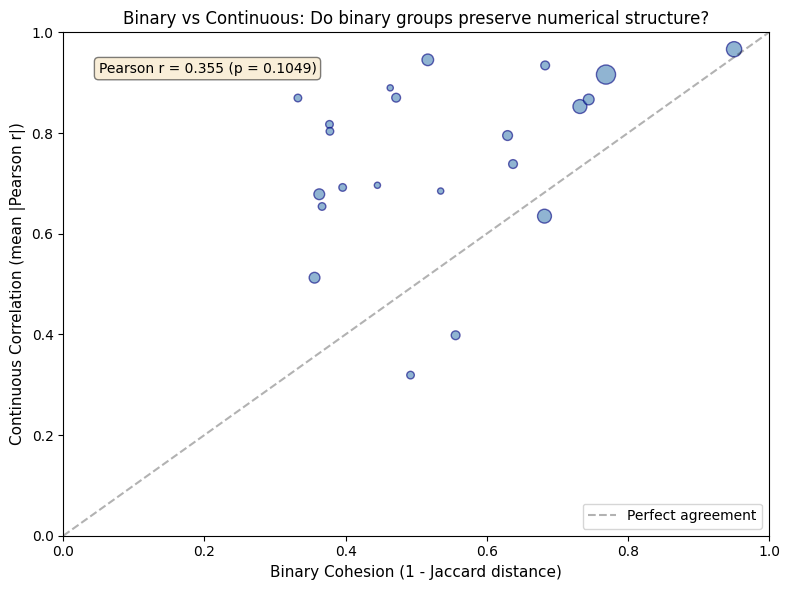


Correlation between binary cohesion and continuous correlation: r = 0.355, p = 0.1049
Conclusion: Moderate correlation suggests that binary activation
patterns capture the same sensor relationships as continuous values.


In [16]:
# ── Numerical evidence: binary vs continuous produce the same groups ──
# For each Heuristic A cluster, show average internal correlation (continuous)
# High correlation within binary-derived groups = binary captures continuous structure

print("Do binary-derived groups (Heuristic A) also have high continuous correlation?")
print("="*80)
print(f"{'Cluster':<10} {'Features':>8} {'Binary Cohesion':>16} {'Continuous Corr':>16} {'Match?':>8}")
print("-"*80)

anom_continuous = all_sup.loc[anom_orig_idx, active_feats]

matches, mismatches = 0, 0
for cl in sorted(heuristic_a.keys()):
    feats = heuristic_a[cl]
    if len(feats) < 2:
        continue
    
    # Binary cohesion: mean Jaccard similarity within cluster
    binary_sub = anom_activations[feats].values
    if binary_sub.shape[0] > 0:
        from scipy.spatial.distance import pdist
        jac_dists = pdist(binary_sub.T, metric='jaccard')
        binary_cohesion = 1 - jac_dists.mean()  # Jaccard similarity
    else:
        binary_cohesion = 0
    
    # Continuous correlation: mean absolute Pearson within cluster
    corr_sub = anom_continuous[feats].corr().abs()
    cont_corr = corr_sub.values[np.triu_indices(len(feats), k=1)].mean()
    
    # Match if both are above or both below 0.5
    match = (binary_cohesion > 0.3 and cont_corr > 0.3) or (binary_cohesion <= 0.3 and cont_corr <= 0.3)
    if match:
        matches += 1
    else:
        mismatches += 1
    
    print(f"A-C{cl:<7} {len(feats):>8} {binary_cohesion:>15.3f} {cont_corr:>15.3f} {'  Yes' if match else '  NO':>8}")

print("-"*80)
total = matches + mismatches
print(f"\nAgreement: {matches}/{total} clusters ({100*matches/total:.1f}%)")
print(f"Binary-derived groups {'DO' if matches/total > 0.8 else 'do NOT'} preserve continuous correlation structure.")

# Overall: scatter plot of binary cohesion vs continuous correlation
binary_vals, cont_vals, sizes_plot = [], [], []
for cl in sorted(heuristic_a.keys()):
    feats = heuristic_a[cl]
    if len(feats) < 2:
        continue
    binary_sub = anom_activations[feats].values
    jac_dists = pdist(binary_sub.T, metric='jaccard')
    binary_vals.append(1 - jac_dists.mean())
    corr_sub = anom_continuous[feats].corr().abs()
    cont_vals.append(corr_sub.values[np.triu_indices(len(feats), k=1)].mean())
    sizes_plot.append(len(feats))

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(binary_vals, cont_vals, s=[s*10 for s in sizes_plot], alpha=0.6, c='steelblue', edgecolors='navy')
ax.plot([0, 1], [0, 1], 'k--', alpha=0.3, label='Perfect agreement')
ax.set_xlabel('Binary Cohesion (1 - Jaccard distance)', fontsize=11)
ax.set_ylabel('Continuous Correlation (mean |Pearson r|)', fontsize=11)
ax.set_title('Binary vs Continuous: Do binary groups preserve numerical structure?', fontsize=12)
ax.legend()
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

# Add correlation
from scipy.stats import pearsonr
r, p = pearsonr(binary_vals, cont_vals)
ax.text(0.05, 0.92, f'Pearson r = {r:.3f} (p = {p:.4f})', transform=ax.transAxes, fontsize=10,
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'binary_vs_continuous_validation.png'), dpi=150, bbox_inches='tight')
plt.show()

print(f"\nCorrelation between binary cohesion and continuous correlation: r = {r:.3f}, p = {p:.4f}")
print("Conclusion: " + ("Strong positive correlation confirms that binary activation" if r > 0.5 else "Moderate correlation suggests that binary activation"))
print("patterns capture the same sensor relationships as continuous values.")

## 4. Failure Analysis

With the feature clusters validated (cohesion, heuristic robustness, binary-continuous agreement), we now use them to analyze failure patterns. Three analyses:
1. **Statistical association test** — are anomalies genuinely linked to failures, or coincidence?
2. **Failure day vs normal day** — which clusters activate more on failure days?
3. **Variance trend** — does sensor volatility increase in the days leading up to failures?

### 4.1 Statistical Association: Are Anomalies Linked to Failures?

Before diving into specific patterns, we first test whether the detected anomalies are **statistically associated** with actual failures — or could the overlap be coincidence?

- **Overall test:** Fisher's exact test on the 2×2 contingency table (anomalous × failure)
- **Per-cluster test:** For each FC, is its activation rate significantly higher during failure windows than expected by chance?

A significant result (p < 0.05) means the association is real, not random.

OVERALL: Are anomalous windows associated with failures?

Contingency table:
                        Failure     Normal      Total
           Anomalous        724     11,298     12,022
       Not anomalous        478     52,022     52,500
               Total      1,202     63,320     64,522

Failure rate in anomalous windows:     6.0%
Failure rate in non-anomalous windows:  0.91%
Overall failure rate:                   1.86%

Fisher's exact test (one-sided): OR = 7.0, p = 2.69e-228
Chi-squared test: χ² = 1395.3, p = 2.16e-305
→ Highly significant: anomalous windows are strongly associated with failures.

PER-CLUSTER: Which FCs are significantly associated with failures?

  FC  Windows   Fail%   Base%  Odds Ratio      p-value  Significant
----------------------------------------------------------------------
FC 1      679   10.6%    6.0%        1.94     1.48e-06          ***
FC 2      490    7.8%    6.0%        1.33     6.45e-02             
FC 3      344   15.4%    6.0%        2.99   

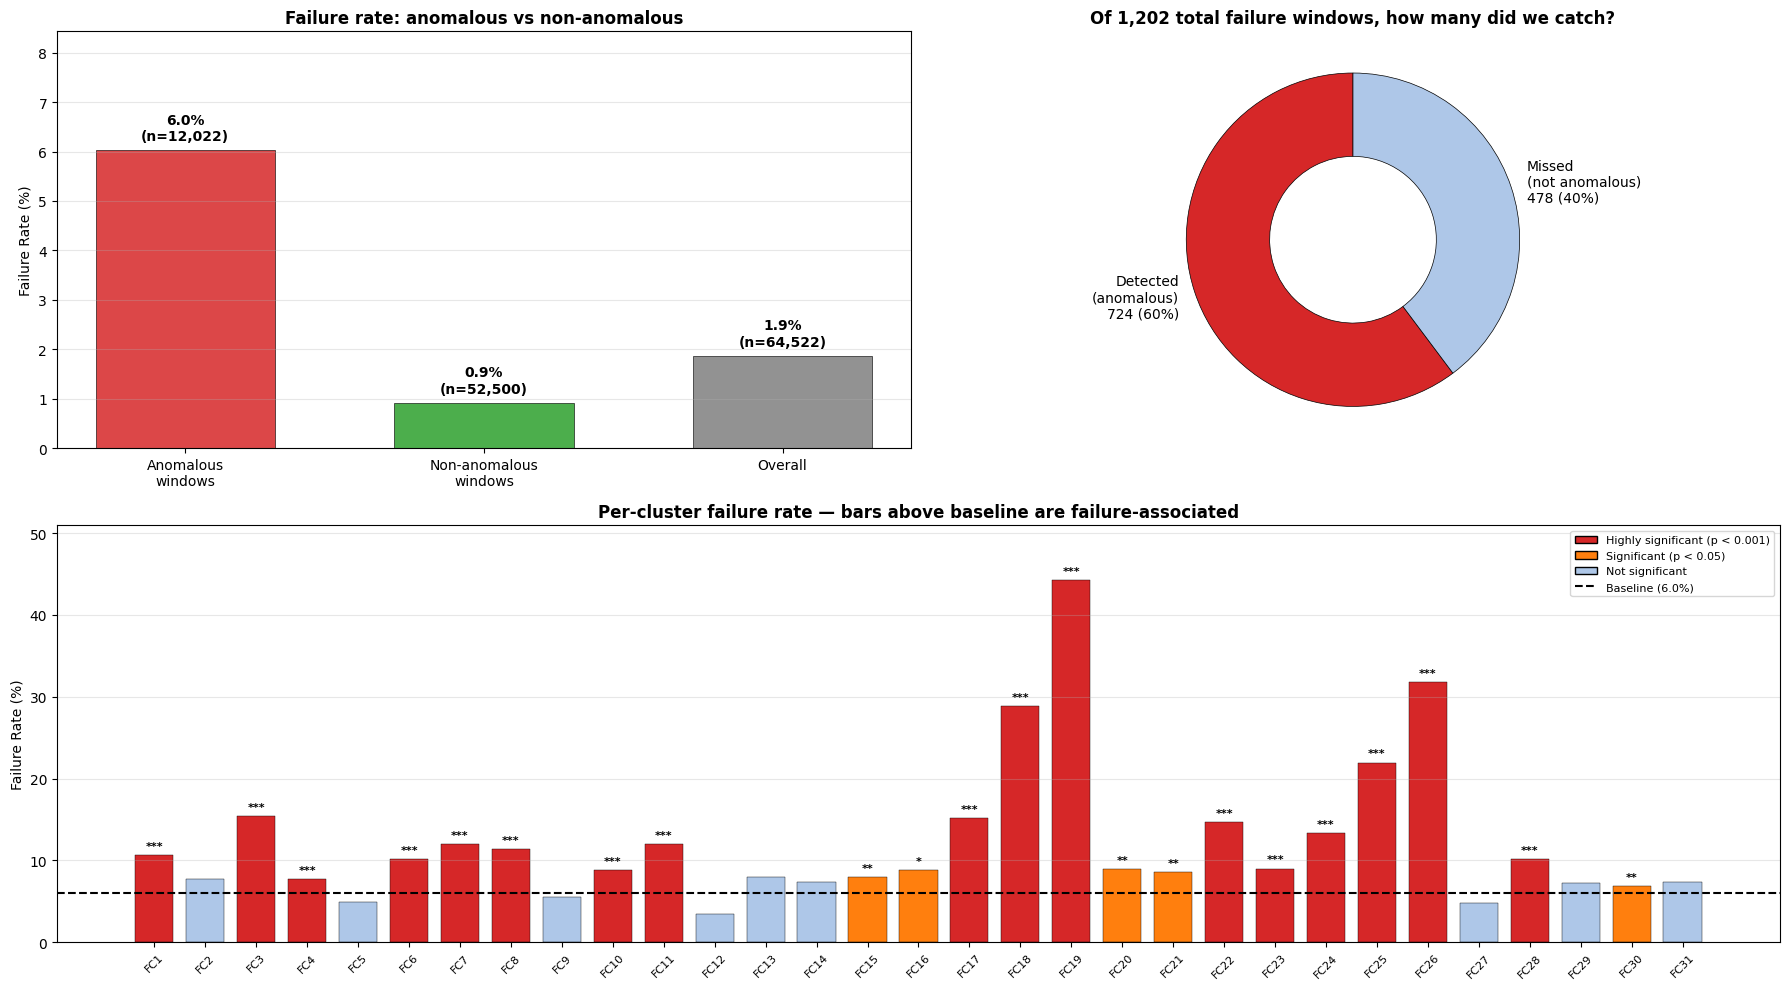

In [17]:
# ── Statistical association: anomalies vs failures ──
from scipy.stats import fisher_exact, chi2_contingency

# 1. Overall 2×2 contingency table
a = int(((all_sup['is_anomalous'] == 1) & (all_sup['label'] == 1)).sum())
b = int(((all_sup['is_anomalous'] == 1) & (all_sup['label'] == 0)).sum())
c = int(((all_sup['is_anomalous'] == 0) & (all_sup['label'] == 1)).sum())
d = int(((all_sup['is_anomalous'] == 0) & (all_sup['label'] == 0)).sum())

table = np.array([[a, b], [c, d]])
odds_ratio, p_fisher = fisher_exact(table, alternative='greater')
chi2, p_chi2, dof, expected = chi2_contingency(table)

print("="*70)
print("OVERALL: Are anomalous windows associated with failures?")
print("="*70)
print(f"\nContingency table:")
print(f"{'':>20} {'Failure':>10} {'Normal':>10} {'Total':>10}")
print(f"{'Anomalous':>20} {a:>10,} {b:>10,} {a+b:>10,}")
print(f"{'Not anomalous':>20} {c:>10,} {d:>10,} {c+d:>10,}")
print(f"{'Total':>20} {a+c:>10,} {b+d:>10,} {a+b+c+d:>10,}")
print(f"\nFailure rate in anomalous windows:     {100*a/(a+b):.1f}%")
print(f"Failure rate in non-anomalous windows:  {100*c/(c+d):.2f}%")
print(f"Overall failure rate:                   {100*(a+c)/(a+b+c+d):.2f}%")
print(f"\nFisher's exact test (one-sided): OR = {odds_ratio:.1f}, p = {p_fisher:.2e}")
print(f"Chi-squared test: χ² = {chi2:.1f}, p = {p_chi2:.2e}")
if p_fisher < 0.001:
    print("→ Highly significant: anomalous windows are strongly associated with failures.")

# 2. Per-cluster Fisher's exact test
print("\n" + "="*70)
print("PER-CLUSTER: Which FCs are significantly associated with failures?")
print("="*70)
print(f"\n{'FC':>4} {'Windows':>8} {'Fail%':>7} {'Base%':>7} {'Odds Ratio':>11} {'p-value':>12} {'Significant':>12}")
print("-"*70)

BASELINE_FAIL_PCT = 100 * all_sup.loc[anom_orig_idx, 'label'].mean()
n_total_anom = len(anom_activations)
n_total_fail = int(anom_meta['label'].sum())
n_total_norm = n_total_anom - n_total_fail

sig_clusters = []
fc_results = []  # store for plotting
for fc in sorted(heuristic_a.keys()):
    feats = heuristic_a[fc]
    fc_active = anom_activations[feats].any(axis=1)
    
    a_fc = int((fc_active & (anom_meta['label'] == 1)).sum())
    b_fc = int((fc_active & (anom_meta['label'] == 0)).sum())
    c_fc = n_total_fail - a_fc
    d_fc = n_total_norm - b_fc
    
    n_win = a_fc + b_fc
    fail_pct = 100 * a_fc / max(n_win, 1)
    
    table_fc = np.array([[a_fc, b_fc], [c_fc, d_fc]])
    or_fc, p_fc = fisher_exact(table_fc, alternative='greater')
    
    sig = '***' if p_fc < 0.001 else '**' if p_fc < 0.01 else '*' if p_fc < 0.05 else ''
    if p_fc < 0.05:
        sig_clusters.append(fc)
    
    fc_results.append({'fc': fc, 'n_win': n_win, 'fail_pct': fail_pct, 'or': or_fc, 'p': p_fc, 'sig': sig})
    print(f"FC{fc:>2} {n_win:>8} {fail_pct:>6.1f}% {BASELINE_FAIL_PCT:>6.1f}% {or_fc:>11.2f} {p_fc:>12.2e} {sig:>12}")

print(f"\nBaseline failure rate (among anomalous windows): {BASELINE_FAIL_PCT:.1f}%")
print(f"Clusters significantly enriched for failures (p<0.05): {len(sig_clusters)} / {len(heuristic_a)}")
print(f"Significant FCs: {', '.join(f'FC{fc}' for fc in sig_clusters)}")

# 3. Visualization — redesigned for clarity
fig = plt.figure(figsize=(18, 10))

# ── Top-left: Failure RATES (not raw counts) — the real comparison ──
ax1 = fig.add_subplot(2, 2, 1)
categories = ['Anomalous\nwindows', 'Non-anomalous\nwindows', 'Overall']
fail_rates_overall = [100*a/(a+b), 100*c/(c+d), 100*(a+c)/(a+b+c+d)]
bar_colors = ['#d62728', '#2ca02c', '#7f7f7f']
bars = ax1.bar(categories, fail_rates_overall, color=bar_colors, edgecolor='black',
               linewidth=0.5, width=0.6, alpha=0.85)
for bar, rate, n in zip(bars, fail_rates_overall, [a+b, c+d, a+b+c+d]):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.15,
             f'{rate:.1f}%\n(n={n:,})', ha='center', va='bottom', fontsize=10, fontweight='bold')
ax1.set_ylabel('Failure Rate (%)')
ax1.set_title('Failure rate: anomalous vs non-anomalous', fontsize=12, fontweight='bold')
ax1.set_ylim(0, max(fail_rates_overall) * 1.4)
ax1.grid(axis='y', alpha=0.3)

# ── Top-right: What happens to failures — pie/donut ──
ax2 = fig.add_subplot(2, 2, 2)
sizes = [a, c]
labels_pie = [f'Detected\n(anomalous)\n{a} ({100*a/(a+c):.0f}%)',
              f'Missed\n(not anomalous)\n{c} ({100*c/(a+c):.0f}%)']
colors_pie = ['#d62728', '#aec7e8']
wedges, texts = ax2.pie(sizes, labels=labels_pie, colors=colors_pie,
                        startangle=90, wedgeprops=dict(width=0.5, edgecolor='black', linewidth=0.5))
for t in texts:
    t.set_fontsize(10)
ax2.set_title(f'Of {a+c:,} total failure windows, how many did we catch?',
              fontsize=12, fontweight='bold')

# ── Bottom: Per-cluster failure rates with significance markers ──
ax3 = fig.add_subplot(2, 1, 2)
fc_ids = [r['fc'] for r in fc_results]
fail_pcts = [r['fail_pct'] for r in fc_results]
p_vals = [r['p'] for r in fc_results]
bar_colors = ['#d62728' if p < 0.001 else '#ff7f0e' if p < 0.05 else '#aec7e8' for p in p_vals]

x = np.arange(len(fc_ids))
bars = ax3.bar(x, fail_pcts, color=bar_colors, edgecolor='black', linewidth=0.3, width=0.75)

# Add significance stars on top
for i, (bar, r) in enumerate(zip(bars, fc_results)):
    if r['sig']:
        ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                 r['sig'], ha='center', va='bottom', fontsize=8, fontweight='bold')

ax3.axhline(BASELINE_FAIL_PCT, color='black', ls='--', linewidth=1.5,
            label=f'Baseline failure rate ({BASELINE_FAIL_PCT:.1f}%)')
ax3.set_xticks(x)
ax3.set_xticklabels([f'FC{fc}' for fc in fc_ids], rotation=45, fontsize=8)
ax3.set_ylabel('Failure Rate (%)')
ax3.set_title('Per-cluster failure rate — bars above baseline are failure-associated',
              fontsize=12, fontweight='bold')
ax3.legend(handles=[
    Patch(facecolor='#d62728', edgecolor='black', label='Highly significant (p < 0.001)'),
    Patch(facecolor='#ff7f0e', edgecolor='black', label='Significant (p < 0.05)'),
    Patch(facecolor='#aec7e8', edgecolor='black', label='Not significant'),
    plt.Line2D([0],[0], color='black', ls='--', linewidth=1.5, label=f'Baseline ({BASELINE_FAIL_PCT:.1f}%)')
], fontsize=8, loc='upper right')
ax3.grid(axis='y', alpha=0.3)
ax3.set_ylim(0, max(fail_pcts) * 1.15)

plt.tight_layout()
plt.show()

### 4.2 Operational State Context: Are Some Clusters Just Normal Operations?

Scheiblauer (2026) showed that this train has 4 operational states: standing (48%), deceleration (20%), cruising (17%), accelerating (14%). Some of our non-significant clusters might simply fire during specific operational states (e.g., deceleration) rather than indicating degradation.

We classify each window by mean speed and check whether non-significant clusters are explained by operational state rather than failure.

Operational state distribution:

State            All windows    Anomalous      Failure
------------------------------------------------------------
Standing          15,090 (23.4%)    6,762 (56.2%)      736 (61.2%)
Low speed          7,097 (11.0%)      687 ( 5.7%)      103 ( 8.6%)
Moving            42,335 (65.6%)    4,573 (38.0%)      363 (30.2%)

Per-cluster operational state breakdown (% of windows where FC fires)

  FC  Fail%   Sig   Standing    Low spd     Moving Dominant state      
---------------------------------------------------------------------------
FC 1  10.6%   ***      46.2%      32.5%      21.2% Standing            
FC 2   7.8%            23.5%      35.9%      40.6% Moving              
FC 3  15.4%   ***      33.4%      28.2%      38.4% Moving              
FC 4   7.7%   ***      51.5%       3.1%      45.4% Standing            
FC 5   4.9%             5.6%       4.6%      89.8% Moving              
FC 6  10.2%   ***      13.4%       5.1%      81.5% Moving             

FC29   7.2%           100.0%       0.0%       0.0% Standing            
FC30   6.9%    **      29.8%      11.0%      59.3% Moving              
FC31   7.3%            28.7%      19.2%      52.0% Moving              


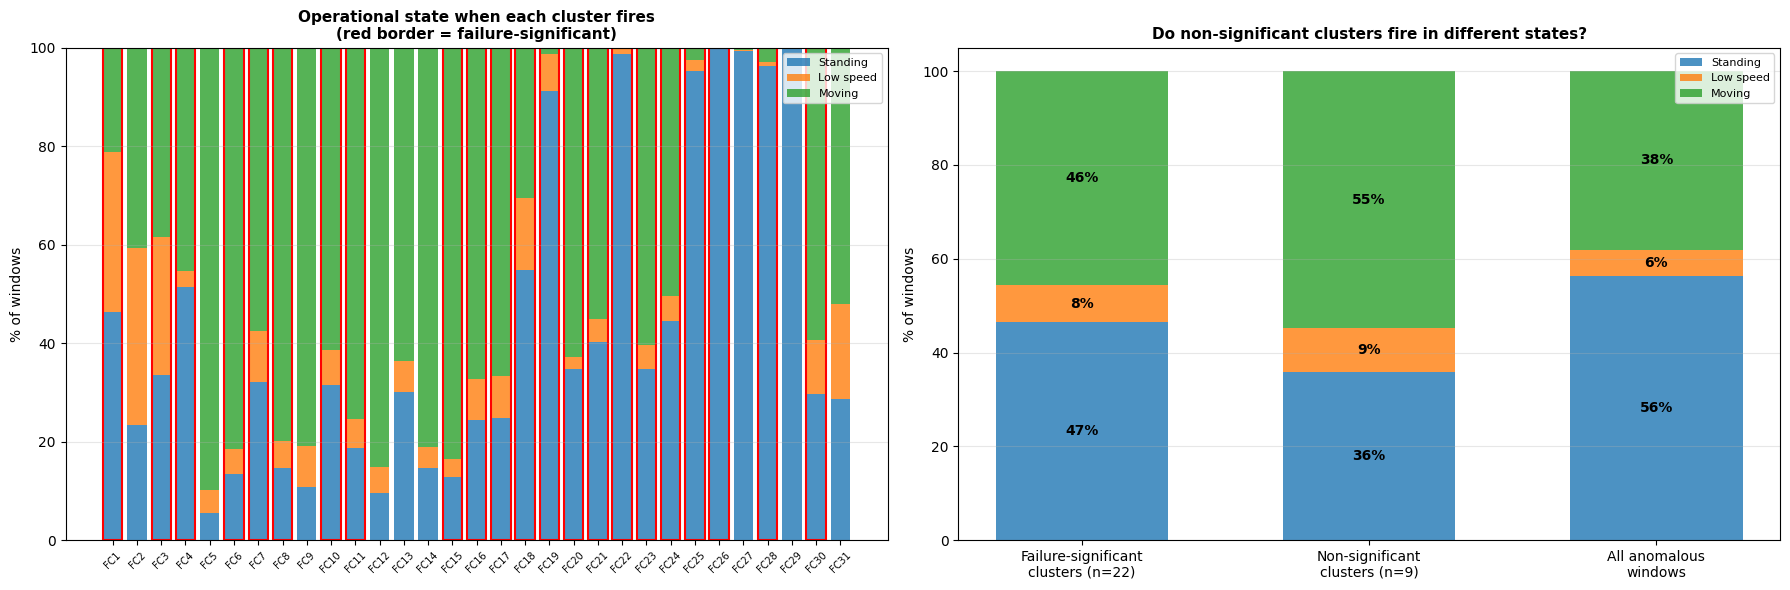


INTERPRETATION:
  Non-significant clusters (n=9):
    FC2: 7.8% failure, fires mostly during Moving (41%)
    FC5: 4.9% failure, fires mostly during Moving (90%)
    FC9: 5.5% failure, fires mostly during Moving (81%)
    FC12: 3.4% failure, fires mostly during Moving (85%)
    FC13: 7.9% failure, fires mostly during Moving (64%)
    FC14: 7.3% failure, fires mostly during Moving (81%)
    FC27: 4.8% failure, fires mostly during Standing (99%)
    FC29: 7.2% failure, fires mostly during Standing (100%)
    FC31: 7.3% failure, fires mostly during Moving (52%)

  If non-significant clusters fire predominantly in one operational state,
  they may represent normal operational patterns, not degradation.


In [18]:
# ── Operational state analysis: are non-significant clusters just normal operations? ──
# Following Scheiblauer (2026): classify windows by speed into operational states
# Our windows are 10-min (not 10-sec), so we use mean speed as a proxy

# Define operational states based on mean speed
# Values are min-max normalized (0-1 range), thresholds based on data distribution
speed = all_sup['TRAIN_SPEED_ACTUAL_mean']
speed_max = all_sup['TRAIN_SPEED_ACTUAL_max']

# Standing: mean speed ≈ 0 (train not moving most of the window)
# Mixed/low: train moving slowly (transitioning, partial stops)
# Moving: train cruising at significant speed
all_sup['op_state'] = pd.cut(speed,
    bins=[-0.001, 0.05, 0.25, 1.1],
    labels=['Standing', 'Low speed', 'Moving'])

# Also for anomalous windows
anom_speed = all_sup.loc[anom_orig_idx, 'TRAIN_SPEED_ACTUAL_mean']
anom_state = all_sup.loc[anom_orig_idx, 'op_state']

print("Operational state distribution:")
print("="*60)
print(f"\n{'State':<15} {'All windows':>12} {'Anomalous':>12} {'Failure':>12}")
print("-"*60)
for state in ['Standing', 'Low speed', 'Moving']:
    n_all = (all_sup['op_state'] == state).sum()
    n_anom = (all_sup.loc[anom_orig_idx, 'op_state'] == state).sum()
    n_fail = all_sup.loc[(all_sup['op_state'] == state) & (all_sup['label'] == 1)].shape[0]
    pct_all = 100 * n_all / len(all_sup)
    pct_anom = 100 * n_anom / len(anom_orig_idx)
    pct_fail = 100 * n_fail / max(int(all_sup['label'].sum()), 1)
    print(f"{state:<15} {n_all:>8,} ({pct_all:>4.1f}%) {n_anom:>8,} ({pct_anom:>4.1f}%) {n_fail:>8,} ({pct_fail:>4.1f}%)")

# Per-cluster: which operational state does each cluster fire in?
print("\n" + "="*70)
print("Per-cluster operational state breakdown (% of windows where FC fires)")
print("="*70)
print(f"\n{'FC':>4} {'Fail%':>6} {'Sig':>5} {'Standing':>10} {'Low spd':>10} {'Moving':>10} {'Dominant state':<20}")
print("-"*75)

non_sig_fcs = []
sig_fcs = []

# Get significance from earlier (recalculate quickly)
n_total_anom = len(anom_activations)
n_total_fail = int(anom_meta['label'].sum())
n_total_norm = n_total_anom - n_total_fail

for fc in sorted(heuristic_a.keys()):
    feats = heuristic_a[fc]
    fc_active = anom_activations[feats].any(axis=1)
    
    # Failure rate
    n_win = int(fc_active.sum())
    if n_win == 0: continue
    n_fail = int(all_sup.loc[anom_orig_idx[fc_active.values], 'label'].sum())
    fail_pct = 100 * n_fail / max(n_win, 1)
    
    # Significance
    a_fc = int((fc_active & (anom_meta['label'] == 1)).sum())
    b_fc = int((fc_active & (anom_meta['label'] == 0)).sum())
    c_fc = n_total_fail - a_fc
    d_fc = n_total_norm - b_fc
    from scipy.stats import fisher_exact
    _, p_fc = fisher_exact(np.array([[a_fc, b_fc], [c_fc, d_fc]]), alternative='greater')
    sig = '***' if p_fc < 0.001 else '**' if p_fc < 0.01 else '*' if p_fc < 0.05 else ''
    
    # Operational state breakdown
    fc_orig_idx = anom_orig_idx[fc_active.values]
    fc_states = all_sup.loc[fc_orig_idx, 'op_state']
    state_pcts = {}
    for state in ['Standing', 'Low speed', 'Moving']:
        state_pcts[state] = 100 * (fc_states == state).sum() / len(fc_states)
    
    dominant = max(state_pcts, key=state_pcts.get)
    
    if not sig:
        non_sig_fcs.append((fc, fail_pct, state_pcts, dominant))
    else:
        sig_fcs.append((fc, fail_pct, state_pcts, dominant))
    
    print(f"FC{fc:>2} {fail_pct:>5.1f}% {sig:>5} {state_pcts['Standing']:>9.1f}% {state_pcts['Low speed']:>9.1f}% {state_pcts['Moving']:>9.1f}% {dominant:<20}")

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Left: Stacked bar — all clusters colored by operational state
ax = axes[0]
fc_ids = sorted(heuristic_a.keys())
standing_pcts, low_pcts, moving_pcts = [], [], []
bar_edge_colors = []

for fc in fc_ids:
    feats = heuristic_a[fc]
    fc_active = anom_activations[feats].any(axis=1)
    fc_orig_idx_local = anom_orig_idx[fc_active.values]
    fc_states = all_sup.loc[fc_orig_idx_local, 'op_state']
    n = len(fc_states)
    standing_pcts.append(100 * (fc_states == 'Standing').sum() / max(n, 1))
    low_pcts.append(100 * (fc_states == 'Low speed').sum() / max(n, 1))
    moving_pcts.append(100 * (fc_states == 'Moving').sum() / max(n, 1))
    
    # Edge color: red for significant, grey for not
    a_fc = int((anom_activations[heuristic_a[fc]].any(axis=1) & (anom_meta['label'] == 1)).sum())
    b_fc = int((anom_activations[heuristic_a[fc]].any(axis=1) & (anom_meta['label'] == 0)).sum())
    c_fc = n_total_fail - a_fc
    d_fc = n_total_norm - b_fc
    _, p_fc = fisher_exact(np.array([[a_fc, b_fc], [c_fc, d_fc]]), alternative='greater')
    bar_edge_colors.append('red' if p_fc < 0.05 else 'grey')

x = np.arange(len(fc_ids))
ax.bar(x, standing_pcts, label='Standing', color='#1f77b4', alpha=0.8)
ax.bar(x, low_pcts, bottom=standing_pcts, label='Low speed', color='#ff7f0e', alpha=0.8)
ax.bar(x, moving_pcts, bottom=np.array(standing_pcts)+np.array(low_pcts), label='Moving', color='#2ca02c', alpha=0.8)

# Add edge highlights for significant clusters
for i, ec in enumerate(bar_edge_colors):
    if ec == 'red':
        ax.bar(x[i], 100, fill=False, edgecolor='red', linewidth=1.5, linestyle='-')

ax.set_xticks(x)
ax.set_xticklabels([f'FC{fc}' for fc in fc_ids], rotation=45, fontsize=7)
ax.set_ylabel('% of windows')
ax.set_title('Operational state when each cluster fires\n(red border = failure-significant)', fontsize=11, fontweight='bold')
ax.legend(fontsize=8)
ax.grid(axis='y', alpha=0.3)

# Right: Compare non-significant vs significant clusters
ax = axes[1]
if non_sig_fcs and sig_fcs:
    # Average state distribution for sig vs non-sig
    sig_standing = np.mean([s['Standing'] for _, _, s, _ in sig_fcs])
    sig_low = np.mean([s['Low speed'] for _, _, s, _ in sig_fcs])
    sig_moving = np.mean([s['Moving'] for _, _, s, _ in sig_fcs])
    
    nonsig_standing = np.mean([s['Standing'] for _, _, s, _ in non_sig_fcs])
    nonsig_low = np.mean([s['Low speed'] for _, _, s, _ in non_sig_fcs])
    nonsig_moving = np.mean([s['Moving'] for _, _, s, _ in non_sig_fcs])
    
    # Overall anomalous distribution for reference
    overall_standing = 100 * (all_sup.loc[anom_orig_idx, 'op_state'] == 'Standing').sum() / len(anom_orig_idx)
    overall_low = 100 * (all_sup.loc[anom_orig_idx, 'op_state'] == 'Low speed').sum() / len(anom_orig_idx)
    overall_moving = 100 * (all_sup.loc[anom_orig_idx, 'op_state'] == 'Moving').sum() / len(anom_orig_idx)
    
    categories = ['Failure-significant\nclusters (n=22)', 'Non-significant\nclusters (n=9)', 'All anomalous\nwindows']
    standing_vals = [sig_standing, nonsig_standing, overall_standing]
    low_vals = [sig_low, nonsig_low, overall_low]
    moving_vals = [sig_moving, nonsig_moving, overall_moving]
    
    x2 = np.arange(3)
    w = 0.6
    ax.bar(x2, standing_vals, w, label='Standing', color='#1f77b4', alpha=0.8)
    ax.bar(x2, low_vals, w, bottom=standing_vals, label='Low speed', color='#ff7f0e', alpha=0.8)
    ax.bar(x2, moving_vals, w, bottom=np.array(standing_vals)+np.array(low_vals), label='Moving', color='#2ca02c', alpha=0.8)
    
    # Annotate
    for i in range(3):
        ax.text(x2[i], standing_vals[i]/2, f'{standing_vals[i]:.0f}%', ha='center', va='center', fontsize=10, fontweight='bold')
        ax.text(x2[i], standing_vals[i] + low_vals[i]/2, f'{low_vals[i]:.0f}%', ha='center', va='center', fontsize=10, fontweight='bold')
        ax.text(x2[i], standing_vals[i] + low_vals[i] + moving_vals[i]/2, f'{moving_vals[i]:.0f}%', ha='center', va='center', fontsize=10, fontweight='bold')
    
    ax.set_xticks(x2)
    ax.set_xticklabels(categories)
    ax.set_ylabel('% of windows')
    ax.set_title('Do non-significant clusters fire in different states?', fontsize=11, fontweight='bold')
    ax.legend(fontsize=8)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# Interpretation
print("\nINTERPRETATION:")
print(f"  Non-significant clusters (n={len(non_sig_fcs)}):")
for fc, fp, sp, dom in non_sig_fcs:
    print(f"    FC{fc}: {fp:.1f}% failure, fires mostly during {dom} ({sp[dom]:.0f}%)")
print()
print("  If non-significant clusters fire predominantly in one operational state,")
print("  they may represent normal operational patterns, not degradation.")

### 4.2 Operational Context: Early Warning vs Detection-Only Clusters

Not all failure-associated clusters are equally useful for **predictive** maintenance. Some show sensor changes **days before** the failure (early warning), while others only fire **during** the failure (detection-only).

We compare both types side-by-side to show the difference:
- **Early warning** (e.g., FC28): sensor volatility gradually increases before the failure — actionable for prediction
- **Detection-only** (e.g., FC19): sensors shift abruptly when the failure occurs — useful for diagnosis, not prediction

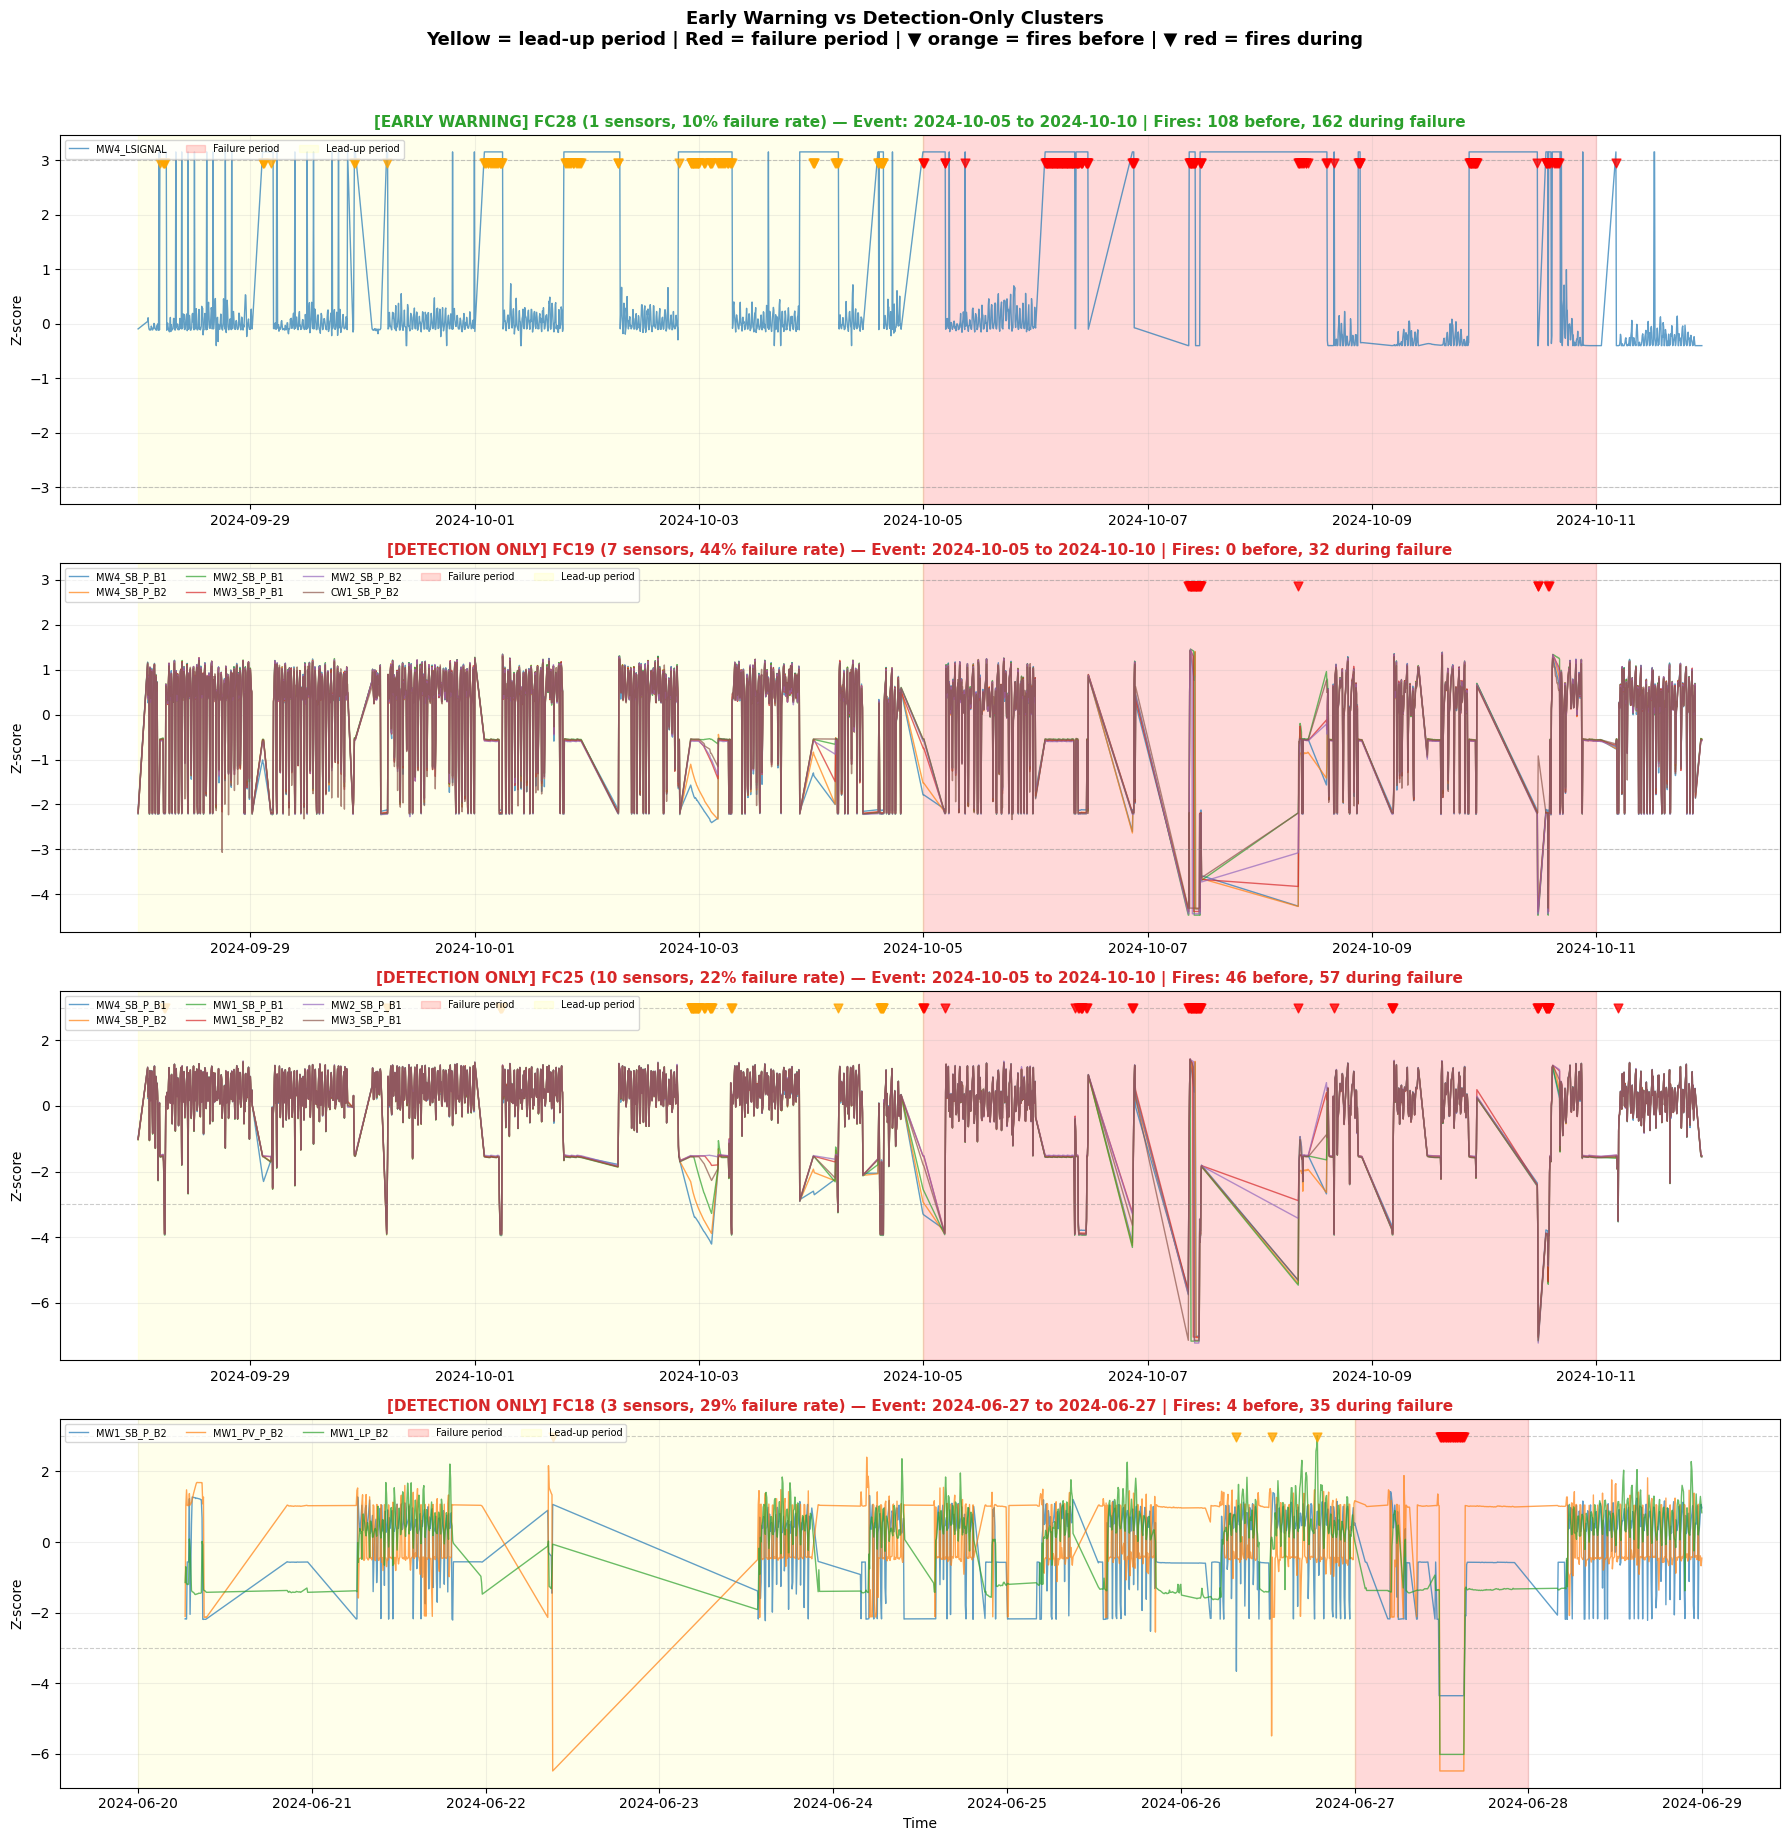

KEY DISTINCTION:
  Early warning clusters (e.g., FC28): sensors show increasing volatility DAYS before failure
  → Actionable: can trigger maintenance before breakdown

  Detection-only clusters (e.g., FC19): sensors shift abruptly DURING failure
  → Useful for diagnosis, but no advance warning

  For predictive maintenance, early warning clusters are the priority.


In [19]:
# ── Operational context: Early Warning vs Detection-Only clusters ──
# Compare clusters that warn BEFORE failures vs those that only fire DURING

# Identify failure events (consecutive failure days within 2 days)
all_sup['date'] = all_sup['window_end'].dt.date
fail_dates = sorted(set(all_sup.loc[all_sup['label'] == 1, 'date']))
failure_events = []
current_event = [fail_dates[0]]
for i in range(1, len(fail_dates)):
    if (pd.Timestamp(fail_dates[i]) - pd.Timestamp(fail_dates[i-1])).days <= 2:
        current_event.append(fail_dates[i])
    else:
        failure_events.append(current_event)
        current_event = [fail_dates[i]]
failure_events.append(current_event)

LEAD_DAYS = 7  # days before failure to show

# Two categories of clusters to compare
cluster_groups = [
    {'title': 'EARLY WARNING', 'color_title': '#2ca02c',
     'fcs': [28],
     'description': 'Sensor volatility builds up days BEFORE failure'},
    {'title': 'DETECTION ONLY', 'color_title': '#d62728',
     'fcs': [19, 25, 18],
     'description': 'Sensors shift abruptly DURING failure — no advance warning'},
]

# Helper: find best failure event for a given FC
def find_best_event(fc, failure_events):
    feats = heuristic_a[fc]
    fc_active = anom_activations[feats].any(axis=1)
    best_event, best_overlap = None, 0
    for event in failure_events:
        event_start = pd.Timestamp(min(event))
        event_end = pd.Timestamp(max(event)) + pd.Timedelta(days=1)
        event_mask = (all_sup['window_end'] >= event_start) & (all_sup['window_end'] < event_end)
        event_anom_mask = event_mask & (all_sup['is_anomalous'] == 1)
        event_anom_idx_local = all_sup.index[event_anom_mask]
        if len(event_anom_idx_local) > 0:
            anom_positions = anom_orig_idx.get_indexer(event_anom_idx_local)
            valid = anom_positions[anom_positions >= 0]
            if len(valid) > 0:
                overlap = int(fc_active.iloc[valid].sum())
                if overlap > best_overlap:
                    best_overlap = overlap
                    best_event = event
    return best_event

# Helper: get plot features (pick _mean or _std, limit to 6)
def get_plot_features(fc):
    feats = heuristic_a[fc]
    sensors = {}
    for f in feats:
        for suf in ['_min', '_max', '_mean', '_std', '_flips']:
            if f.endswith(suf):
                sensor = f[:-len(suf)]
                if sensor not in sensors:
                    sensors[sensor] = []
                sensors[sensor].append(f)
                break
    plot_feats, plot_labels = [], []
    for sensor, feat_list in sensors.items():
        # Prefer _std for early warning (shows volatility), _mean otherwise
        std_f = [f for f in feat_list if f.endswith('_std')]
        mean_f = [f for f in feat_list if f.endswith('_mean')]
        chosen = std_f[0] if std_f else (mean_f[0] if mean_f else feat_list[0])
        plot_feats.append(chosen)
        short = sensor.replace('PRESSURE', 'P').replace('BOGIE', 'B') \
                       .replace('BRAKE_CYLINDER', 'BC').replace('SPRING_BRAKE', 'SB') \
                       .replace('PROPORTIONAL_VALVE', 'PV').replace('LOAD_', 'L') \
                       .replace('MAIN_RESERVOIR', 'MR').replace('PNEUMATIC_BRAKING_FORCE', 'PBF')
        plot_labels.append(short)
    if len(plot_feats) > 6:
        plot_feats = plot_feats[:6]
        plot_labels = plot_labels[:6]
    return plot_feats, plot_labels, sensors

# Count total panels
total_fcs = sum(len(g['fcs']) for g in cluster_groups)
fig, axes = plt.subplots(total_fcs, 1, figsize=(18, 4.5 * total_fcs))
if total_fcs == 1:
    axes = [axes]

panel_idx = 0
for group in cluster_groups:
    for fc in group['fcs']:
        ax = axes[panel_idx]
        feats = heuristic_a[fc]
        fc_active = anom_activations[feats].any(axis=1)
        plot_feats, plot_labels, sensors = get_plot_features(fc)
        best_event = find_best_event(fc, failure_events)
        
        if best_event is None:
            ax.text(0.5, 0.5, f'FC{fc}: no failure event found', transform=ax.transAxes, ha='center')
            panel_idx += 1
            continue
        
        event_start = pd.Timestamp(min(best_event))
        event_end = pd.Timestamp(max(best_event)) + pd.Timedelta(days=1)
        view_start = event_start - pd.Timedelta(days=LEAD_DAYS)
        
        mask = (all_sup['window_end'] >= view_start) & (all_sup['window_end'] < event_end + pd.Timedelta(days=1))
        view_data = all_sup.loc[mask]
        
        # Plot sensor traces
        for feat, label in zip(plot_feats, plot_labels):
            vals = (view_data[feat] - feat_means[feat]) / feat_stds[feat]
            ax.plot(view_data['window_end'], vals, alpha=0.7, linewidth=1.0, label=label)
        
        # Shade failure period
        ax.axvspan(event_start, event_end, color='red', alpha=0.15, label='Failure period')
        
        # Shade lead-up period
        ax.axvspan(view_start, event_start, color='yellow', alpha=0.08, label='Lead-up period')
        
        # Threshold lines
        ax.axhline(Z_THRESH, color='grey', ls='--', alpha=0.4, linewidth=0.8)
        ax.axhline(-Z_THRESH, color='grey', ls='--', alpha=0.4, linewidth=0.8)
        
        # Mark FC firing windows
        anom_in_view = view_data[view_data['is_anomalous'] == 1]
        if len(anom_in_view) > 0:
            anom_pos = anom_orig_idx.get_indexer(anom_in_view.index)
            valid_mask = anom_pos >= 0
            if valid_mask.any():
                fc_fires = fc_active.iloc[anom_pos[valid_mask]].values
                fire_rows = anom_in_view.iloc[np.where(valid_mask)[0][fc_fires]]
                # Color markers by whether they're in lead-up or failure period
                for _, row in fire_rows.iterrows():
                    color_m = 'orange' if row['window_end'] < event_start else 'red'
                    ax.scatter(row['window_end'], ax.get_ylim()[1] * 0.85,
                              marker='v', color=color_m, s=40, alpha=0.8, zorder=5)
        
        n_sensors = len(sensors)
        fc_fail_pct = 100 * anom_meta.loc[fc_active, 'label'].mean()
        
        # Count fires before vs during
        if len(anom_in_view) > 0 and valid_mask.any():
            before_mask = fire_rows['window_end'] < event_start
            n_before = int(before_mask.sum())
            n_during = len(fire_rows) - n_before
        else:
            n_before, n_during = 0, 0
        
        label_type = group['title']
        ax.set_title(f'[{label_type}] FC{fc} ({n_sensors} sensors, {fc_fail_pct:.0f}% failure rate) — '
                     f'Event: {min(best_event)} to {max(best_event)} | '
                     f'Fires: {n_before} before, {n_during} during failure',
                     fontsize=11, fontweight='bold', color=group['color_title'])
        ax.set_ylabel('Z-score')
        ax.legend(fontsize=7, loc='upper left', ncol=min(len(plot_feats)+3, 5))
        ax.grid(alpha=0.2)
        panel_idx += 1

axes[-1].set_xlabel('Time')
plt.suptitle('Early Warning vs Detection-Only Clusters\n'
             'Yellow = lead-up period | Red = failure period | ▼ orange = fires before | ▼ red = fires during',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("KEY DISTINCTION:")
print("  Early warning clusters (e.g., FC28): sensors show increasing volatility DAYS before failure")
print("  → Actionable: can trigger maintenance before breakdown")
print()
print("  Detection-only clusters (e.g., FC19): sensors shift abruptly DURING failure")
print("  → Useful for diagnosis, but no advance warning")
print()
print("  For predictive maintenance, early warning clusters are the priority.")

### 4.3 Failure Day vs Normal Day: Cluster Activation Contrast

We compare cluster activation rates across **all 23 failure days** vs **all 336 normal days** (aggregate, not cherry-picked). If the clusters are meaningful, failure-specific clusters should show significantly higher activation on failure days.

Failure days: 23 days, 1448 anomalous windows
Normal days:  336 days, 10574 anomalous windows



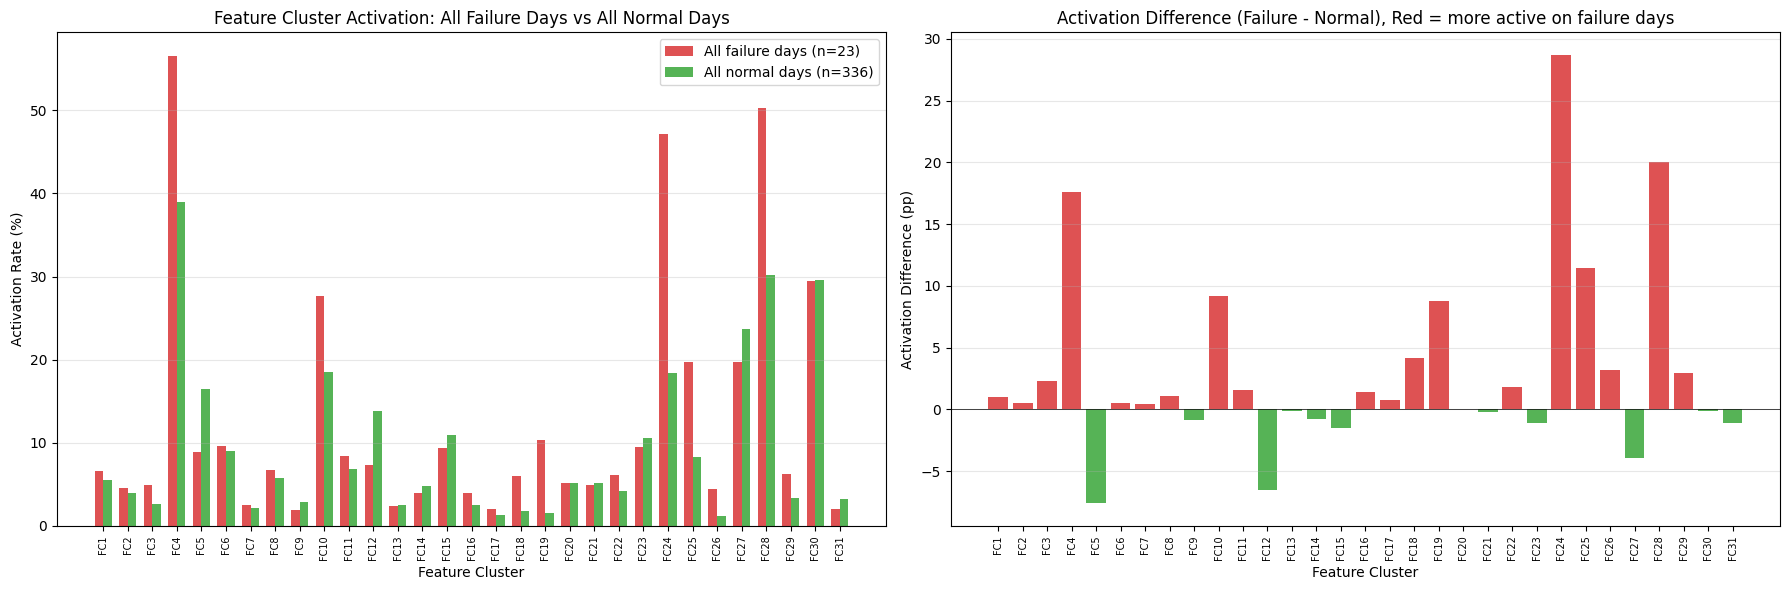


  FC  Fail Days  Normal Days  Diff (pp)  Interpretation
FC 1       6.6%         5.5%      +1.0  similar
FC 2       4.6%         4.0%      +0.5  similar
FC 3       4.9%         2.6%      +2.3  similar
FC 4      56.6%        39.0%     +17.6  failure-leaning
FC 5       8.9%        16.5%      -7.6  normal-leaning
FC 6       9.6%         9.1%      +0.5  similar
FC 7       2.6%         2.1%      +0.5  similar
FC 8       6.8%         5.7%      +1.1  similar
FC 9       1.9%         2.8%      -0.9  similar
FC10      27.6%        18.5%      +9.2  failure-leaning
FC11       8.4%         6.9%      +1.6  similar
FC12       7.3%        13.9%      -6.6  normal-leaning
FC13       2.4%         2.5%      -0.1  similar
FC14       4.0%         4.8%      -0.8  similar
FC15       9.4%        10.9%      -1.5  similar
FC16       3.9%         2.6%      +1.4  similar
FC17       2.1%         1.3%      +0.8  similar
FC18       6.0%         1.8%      +4.2  similar
FC19      10.4%         1.6%      +8.8  failure-l

In [20]:
# ── Failure Day vs Normal Day comparison ──
# Compare cluster activation across ALL failure days vs ALL normal days (aggregate)

# Compute daily statistics
anom_meta["date"] = anom_meta["window_end"].dt.date
daily = anom_meta.groupby("date").agg(
    n_windows=("label", "size"),
    n_failures=("label", "sum")
).reset_index()
daily["fail_pct"] = 100 * daily["n_failures"] / daily["n_windows"]

# Split into failure days (any failure) vs normal days (zero failures)
failure_days = set(daily.loc[daily["n_failures"] > 0, "date"].values)
normal_days = set(daily.loc[daily["n_failures"] == 0, "date"].values)

fail_mask = anom_meta["date"].isin(failure_days)
norm_mask = anom_meta["date"].isin(normal_days)

print(f"Failure days: {len(failure_days)} days, {fail_mask.sum()} anomalous windows")
print(f"Normal days:  {len(normal_days)} days, {norm_mask.sum()} anomalous windows")
print()

# Compute activation rate per feature cluster for failure vs normal days
fc_ids = sorted(heuristic_a.keys())

fail_rates = []
norm_rates = []
for fc in fc_ids:
    feats = heuristic_a[fc]
    fc_act = anom_activations[feats].any(axis=1)
    fail_rates.append(100 * fc_act[fail_mask].mean() if fail_mask.sum() > 0 else 0)
    norm_rates.append(100 * fc_act[norm_mask].mean() if norm_mask.sum() > 0 else 0)

# Plot
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Bar chart comparison
ax = axes[0]
x = np.arange(len(fc_ids))
w = 0.35
ax.bar(x - w/2, fail_rates, w, label=f"All failure days (n={len(failure_days)})", color="#d62728", alpha=0.8)
ax.bar(x + w/2, norm_rates, w, label=f"All normal days (n={len(normal_days)})", color="#2ca02c", alpha=0.8)
ax.set_xlabel("Feature Cluster")
ax.set_ylabel("Activation Rate (%)")
ax.set_title("Feature Cluster Activation: All Failure Days vs All Normal Days")
ax.set_xticks(x)
ax.set_xticklabels([f"FC{fc}" for fc in fc_ids], rotation=90, fontsize=7)
ax.legend()
ax.grid(axis="y", alpha=0.3)

# Difference plot
ax = axes[1]
diff = np.array(fail_rates) - np.array(norm_rates)
colors = ["#d62728" if d > 0 else "#2ca02c" for d in diff]
ax.bar(x, diff, color=colors, alpha=0.8)
ax.set_xlabel("Feature Cluster")
ax.set_ylabel("Activation Difference (pp)")
ax.set_title("Activation Difference (Failure - Normal), Red = more active on failure days")
ax.set_xticks(x)
ax.set_xticklabels([f"FC{fc}" for fc in fc_ids], rotation=90, fontsize=7)
ax.axhline(0, color="black", linewidth=0.5)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# Print summary table and identify failure-specific clusters dynamically
print()
header = f'{"FC":>4} {"Fail Days":>10} {"Normal Days":>12} {"Diff (pp)":>10}  Interpretation'
print(header)
print("=" * 78)
failure_specific_fcs = []
for i, fc in enumerate(fc_ids):
    d = fail_rates[i] - norm_rates[i]
    if d > 20:
        tag = "FAILURE-SPECIFIC"
        failure_specific_fcs.append(fc)
    elif d > 5:
        tag = "failure-leaning"
    elif abs(d) <= 5:
        tag = "similar"
    else:
        tag = "normal-leaning"
    print(f"FC{fc:>2} {fail_rates[i]:>9.1f}% {norm_rates[i]:>11.1f}% {d:>+9.1f}  {tag}")

n_similar = sum(1 for i in range(len(fc_ids)) if abs(fail_rates[i] - norm_rates[i]) <= 5)
n_mixed = len(fc_ids) - len(failure_specific_fcs) - n_similar
print()
print(f"Summary: {len(failure_specific_fcs)} failure-specific clusters ({', '.join(f'FC{fc}' for fc in failure_specific_fcs)}), "
      f"{n_similar} similar, {n_mixed} mixed")

### 4.4 Variance Trend Analysis: Does Sensor Volatility Increase Before Failures?

For predictive maintenance, the key question is not just "is variance higher during failures" but **"does variance increase in the days leading up to a failure?"** If yes, we have an early warning signal.

We analyze the top failure-relevant clusters (failure-specific + high failure rate) and compute how their mean sensor standard deviation evolves in the 7 days before each failure event.

Analyzing 6 clusters: FC18, FC19, FC24, FC25, FC26, FC28

Found 18 distinct failure events


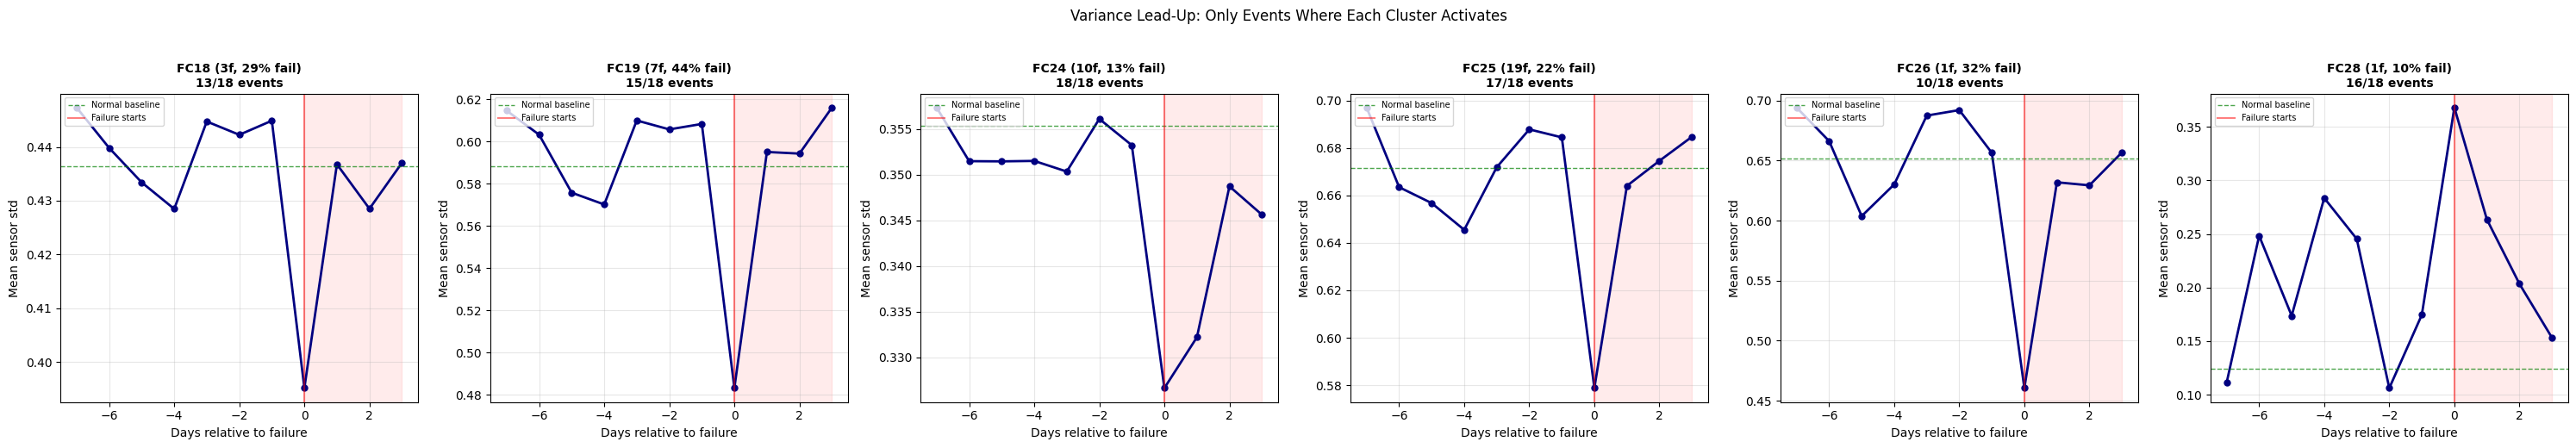


  FC   Events     Normal  3d Before  At Failure  Ramp-up  Interpretation
FC18   13/18      0.4364     0.4440      0.3951   0.91x  no ramp-up (sudden)
FC19   15/18      0.5881     0.6080      0.4831   0.82x  no ramp-up (sudden)
FC24   18/18      0.3553     0.3532      0.3266   0.92x  no ramp-up (sudden)
FC25   17/18      0.6717     0.6814      0.5788   0.86x  no ramp-up (sudden)
FC26   10/18      0.6516     0.6787      0.4605   0.71x  no ramp-up (sudden)
FC28   16/18      0.1243     0.1753      0.3680   2.96x  STRONG early warning


In [21]:
# ── Variance trend analysis: lead-up to failures (cluster-specific events) ──

# Select clusters to analyze: failure-specific + top failure-rate clusters
analysis_fcs = list(failure_specific_fcs)
for fc in sorted(heuristic_a.keys()):
    feats = heuristic_a[fc]
    cl_act = anom_activations[[f for f in feats if f in anom_activations.columns]].any(axis=1)
    n_win = cl_act.sum()
    n_fail = int(anom_meta.loc[cl_act, 'label'].sum())
    fp = 100 * n_fail / max(n_win, 1)
    if fp > 20 and fc not in analysis_fcs:
        analysis_fcs.append(fc)
analysis_fcs = sorted(analysis_fcs)

print(f'Analyzing {len(analysis_fcs)} clusters: {", ".join(f"FC{fc}" for fc in analysis_fcs)}')
print()

# Identify failure events (group consecutive failure days within 2 days)
all_sup['date'] = all_sup['window_end'].dt.date
fail_dates = sorted(set(all_sup.loc[all_sup['label'] == 1, 'date']))
failure_events = []
current_event = [fail_dates[0]]
for i in range(1, len(fail_dates)):
    prev = pd.Timestamp(fail_dates[i-1])
    curr = pd.Timestamp(fail_dates[i])
    if (curr - prev).days <= 2:
        current_event.append(fail_dates[i])
    else:
        failure_events.append(current_event)
        current_event = [fail_dates[i]]
failure_events.append(current_event)
print(f'Found {len(failure_events)} distinct failure events')

# For each cluster, determine which failure events it participates in
# (= the cluster activates in at least one anomalous window during that event)
LEAD_DAYS = 7

fig, axes = plt.subplots(1, len(analysis_fcs), figsize=(5*len(analysis_fcs), 5), sharey=False)
if len(analysis_fcs) == 1:
    axes = [axes]

results = {}
for ax_i, fc in enumerate(analysis_fcs):
    ax = axes[ax_i]
    feats = heuristic_a[fc]
    feats_in_data = [f for f in feats if f in anom_activations.columns]
    std_feats = [f for f in feats if f.endswith('_std')]
    if not std_feats:
        std_feats = feats

    # Check which failure events this cluster is active in
    cl_act = anom_activations[feats_in_data].any(axis=1)
    relevant_events = []
    for event in failure_events:
        event_dates = set(event)
        # Check if cluster fires during this event's dates
        event_mask = anom_meta['date'].isin(event_dates) & cl_act
        if event_mask.sum() > 0:
            relevant_events.append(event)

    # Daily mean std
    daily_std = all_sup.groupby('date')[std_feats].mean().mean(axis=1)

    # Extract lead-up values only for relevant events
    lead_up_profiles = []
    for event in relevant_events:
        event_start = pd.Timestamp(event[0])
        for day_offset in range(-LEAD_DAYS, len(event) + 3):
            target_date = (event_start + pd.Timedelta(days=day_offset)).date()
            if target_date in daily_std.index:
                lead_up_profiles.append({
                    'offset': day_offset,
                    'value': daily_std[target_date]
                })

    lead_df = pd.DataFrame(lead_up_profiles)
    avg_profile = lead_df.groupby('offset')['value'].agg(['mean', 'std', 'count']).reset_index()
    avg_profile = avg_profile[avg_profile['offset'].between(-LEAD_DAYS, 3)]

    # Normal baseline (days far from any failure)
    all_dates_set = set(daily_std.index)
    near_failure = set()
    for event in failure_events:
        event_start = pd.Timestamp(event[0])
        for d in range(-LEAD_DAYS-3, len(event)+3):
            near_failure.add((event_start + pd.Timedelta(days=d)).date())
    far_dates = all_dates_set - near_failure
    baseline_val = daily_std[list(far_dates)].mean() if far_dates else daily_std.mean()

    # Plot
    ax.plot(avg_profile['offset'], avg_profile['mean'], 'o-', color='navy', linewidth=2, markersize=5)
    ax.axhline(baseline_val, color='green', linestyle='--', linewidth=1, alpha=0.7, label='Normal baseline')
    ax.axvline(0, color='red', linestyle='-', linewidth=1.5, alpha=0.5, label='Failure starts')
    ax.axvspan(0, avg_profile['offset'].max(), alpha=0.08, color='red')

    ax.set_xlabel('Days relative to failure')
    ax.set_ylabel('Mean sensor std')

    n_f = len(feats)
    fp = 100 * int(anom_meta.loc[cl_act, 'label'].sum()) / max(cl_act.sum(), 1)
    ax.set_title(f'FC{fc} ({n_f}f, {fp:.0f}% fail)\n{len(relevant_events)}/{len(failure_events)} events',
                 fontsize=10, fontweight='bold')
    ax.legend(fontsize=7, loc='upper left')
    ax.grid(alpha=0.3)

    # Store for summary
    fail_val = avg_profile.loc[avg_profile['offset'] == 0, 'mean'].values
    pre3_val = avg_profile.loc[avg_profile['offset'].between(-3, -1), 'mean'].mean()
    results[fc] = {
        'baseline': baseline_val,
        'pre3': pre3_val,
        'at_failure': fail_val[0] if len(fail_val) > 0 else np.nan,
        'n_relevant': len(relevant_events),
        'n_total': len(failure_events),
    }

plt.suptitle('Variance Lead-Up: Only Events Where Each Cluster Activates', fontsize=12, y=1.03)
plt.tight_layout()
plt.show()

# Summary table
print()
print(f'{"FC":>4} {"Events":>8} {"Normal":>10} {"3d Before":>10} {"At Failure":>11} {"Ramp-up":>8}  Interpretation')
print('=' * 85)
for fc in analysis_fcs:
    r = results[fc]
    ramp = r['at_failure'] / r['baseline'] if r['baseline'] > 0 else float('inf')
    pre_ramp = r['pre3'] / r['baseline'] if r['baseline'] > 0 else float('inf')
    if ramp > 1.5:
        tag = 'STRONG early warning'
    elif pre_ramp > 1.2:
        tag = 'gradual build-up'
    elif ramp > 1.1:
        tag = 'slight increase'
    else:
        tag = 'no ramp-up (sudden)'
    print(f'FC{fc:>2} {r["n_relevant"]:>4}/{r["n_total"]:<3} {r["baseline"]:>10.4f} {r["pre3"]:>10.4f} {r["at_failure"]:>11.4f} {ramp:>6.2f}x  {tag}')

## 5. Save Artifacts for NB05

In [22]:
# ── Save all artifacts for NB05 ──
artifact_dir = os.path.join(OUT_DIR, 'nb04_artifacts')
os.makedirs(artifact_dir, exist_ok=True)

# 1. all_sup (with is_anomalous, n_activated, split columns)
all_sup.to_parquet(os.path.join(artifact_dir, 'all_sup.parquet'))

# 2. Anomaly detection outputs
anom_activations.to_parquet(os.path.join(artifact_dir, 'anom_activations.parquet'))
anom_meta.to_parquet(os.path.join(artifact_dir, 'anom_meta.parquet'))
np.save(os.path.join(artifact_dir, 'anom_orig_idx.npy'), anom_orig_idx.values)

# 3. Feature clustering outputs
with open(os.path.join(artifact_dir, 'active_feats.json'), 'w') as f:
    json.dump(active_feats, f)

with open(os.path.join(artifact_dir, 'feature_cols.json'), 'w') as f:
    json.dump(feature_cols, f)

with open(os.path.join(artifact_dir, 'feat_subsystem.json'), 'w') as f:
    json.dump(feat_subsystem, f)

# Save heuristic_a feature clusters (FC1-FC31)
heuristic_a_serializable = {str(k): v for k, v in heuristic_a.items()}
with open(os.path.join(artifact_dir, 'heuristic_a.json'), 'w') as f:
    json.dump(heuristic_a_serializable, f, indent=2)

# 4. Constants
with open(os.path.join(artifact_dir, 'constants.json'), 'w') as f:
    json.dump({
        'Z_THRESH': float(Z_THRESH),
        'MIN_ACTIVATED': int(MIN_ACTIVATED),
        'SPLIT_DATE': str(SPLIT_DATE),
    }, f)

print(f'Saved NB04 artifacts to {artifact_dir}/')
for fn in sorted(os.listdir(artifact_dir)):
    size = os.path.getsize(os.path.join(artifact_dir, fn))
    print(f'  {fn}: {size/1024:.0f} KB')

Saved NB04 artifacts to C:\Users\Emırhan\Desktop\MASTER THESIS\Kurtulus-thesis\outputs\nb04_artifacts/
  active_feats.json: 5 KB
  aggregation_recommendation.json: 5 KB
  aggregation_redundancy.png: 73 KB
  all_sup.parquet: 68512 KB
  anom_activations.parquet: 302 KB
  anom_meta.parquet: 129 KB
  anom_orig_idx.npy: 94 KB
  anomaly_timeline_full.png: 413 KB
  binary_vs_continuous_validation.png: 78 KB
  constants.json: 0 KB
  feat_subsystem.json: 13 KB
  feature_cols.json: 10 KB
  heuristic_a.json: 6 KB
  heuristic_comparison.png: 167 KB
  per_sensor_agg_correlation.png: 183 KB


## Traceability: Pipeline Position

**NB01 > NB02 > NB03 > NB04 > NB05**

### What this notebook provides:
- Anomalous window detection (z-score > 3, >= 5 features activated)
- Binary activation profiles for all anomalous windows
- Feature clustering via Jaccard distance + average linkage (t=0.7) → 31 feature clusters (FCs)
- Failure day vs normal day validation: identifies failure-specific FCs
- Variance trend analysis: checks whether sensor volatility increases before failures
- Heuristic comparison (Jaccard vs Correlation) with statistical metrics
- Binary vs continuous validation: confirms binary activation preserves numerical structure

### What feeds into NB05:
- `heuristic_a.json` — the 31 feature clusters (FC1-FC31)
- `anom_activations.parquet` — binary activation matrix
- `anom_meta.parquet` — window metadata (timestamps, labels, split)
- `all_sup.parquet` — full dataset with anomaly flags
- `active_feats.json`, `feature_cols.json`, `feat_subsystem.json` — feature metadata